# Objectif 

Illustration d'une méthode d'interpolation de la librairie basée sur la réduction de dimension par apprentissage de variété par la méthode ISOMAP.

Afin d'être plus réaliste on considère ici un jeu de données synthétique généré avec Kraken dans un environnement petit fond légèrement variable. 

In [1]:
import os 
import sys
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from scipy.interpolate import RegularGridInterpolator

In [2]:
root_project = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
sys.path.append(root_project)

from illustration_rtf.src.sensitivity import (
    baseline_env,
    baseline_sig,
    baseline_src_rcv,
    calc_gamma_dist,
    calc_mainlobe_width_3dB,
    calc_monotonicity_domain, 
    # run_single_sensibility_test,
)
# from source.normal_modes import * 
from publication.publication_figure import color, set_subfigures_abc_labels

# Chargement du jeu de données synthétique 

Ce jeu de données est généré à l'aide de la fonction generate_synthetic_dataset dédiée. 

In [3]:
fname = "synthetic_dataset_03112026.nc"  # or "synthetic_dataset_test.nc" (3 frequencies, test mode)
root_data = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\illustration_rtf\data\isomap_rtf_mfp"
fpath = os.path.join(root_data, fname)
ds = xr.open_dataset(fpath, engine="netcdf4", auto_complex=True)
ds

<xarray.Dataset> Size: 8MB
Dimensions:            (sensor: 2, freq: 261, y: 41, x: 41, y_bathy: 71,
                        x_bathy: 66, z_ssp: 11)
Coordinates:
  * sensor             (sensor) <U2 16B 'S1' 'S2'
  * freq               (freq) float64 2kB 20.0 20.5 21.0 ... 149.0 149.5 150.0
  * y                  (y) float64 328B 3e+03 3.05e+03 ... 4.95e+03 5e+03
  * x                  (x) float64 328B 2.5e+03 2.55e+03 ... 4.45e+03 4.5e+03
  * y_bathy            (y_bathy) float64 568B -1e+03 -900.0 ... 5.9e+03 6e+03
  * x_bathy            (x_bathy) float64 528B -1e+03 -900.0 ... 5.4e+03 5.5e+03
  * z_ssp              (z_ssp) float64 88B 0.0 10.0 20.0 ... 120.0 140.0 160.0
Data variables:
    transfer_function  (sensor, freq, y, x) complex64 7MB ...
    valid              (sensor, freq, y, x) int8 877kB ...
    range_m            (sensor, y, x) float32 13kB ...
    azimuth_deg        (sensor, y, x) float32 13kB ...
    lateral_offset_m   (sensor, y, x) float32 13kB ...
    sensor_x           (sensor) float64 16B ...
    sensor_y           (sensor) float64 16B ...
    sensor_depth       (sensor) float64 16B ...
    bathymetry         (y_bathy, x_bathy) float64 37kB ...
    ssp                (z_ssp) float64 88B ...
Attributes: (12/15)
    title:                                   Synthetic transfer functions of ...
    source_depth_m:                          5.0
    fc0_pekeris_hz:                          6.569253234776561
    sediment:                                mud, fluid semi-infinite
    sediment_c_p_m_s:                        1800.0
    sediment_rho_g_cm3:                      1.6
    ...                                      ...
    azimuth_mode:                            binned
    max_lateral_offset_m:                    50.0
    df_hz:                                   0.5
    test_mode:                               0
    method:                                  Reciprocity: KRAKEN source at th...
    delay_note:                              Pressure phase includes the prop...

In [248]:
ds = ds.isel(y=slice(0, 35))

In [249]:
freq = ds["freq"].values
x, y = ds["x"].values, ds["y"].values
names = [str(n) for n in ds["sensor"].values]
sx, sy, sz = ds["sensor_x"].values, ds["sensor_y"].values, ds["sensor_depth"].values
H = ds["transfer_function"].values  # (sensor, freq, y, x), complex64
valid = ds["valid"].values.astype(
    bool
)  # False where KRAKEN/FIELD failed (pressure set to 0)
range_m = ds["range_m"].values  # (sensor, y, x)

print(
    f"{len(names)} sensors, {freq.size} frequencies ({freq.min():.1f} -> {freq.max():.1f} Hz), "
    f"grid {x.size} x {y.size} pixels, fc0 (Pekeris) = {ds.attrs['fc0_pekeris_hz']:.1f} Hz"
)
print(f"valid results: {100 * valid.mean():.1f} %")

2 sensors, 261 frequencies (20.0 -> 150.0 Hz), grid 41 x 35 pixels, fc0 (Pekeris) = 6.6 Hz
valid results: 100.0 %


In [250]:
x_rcv1, y_rcv1, z_rcv1 = sx[0], sy[0], sz[0]
x_rcv2, y_rcv2, z_rcv2 = sx[1], sy[1], sz[1]

## Illustration de la bathy et de la position des capteurs 

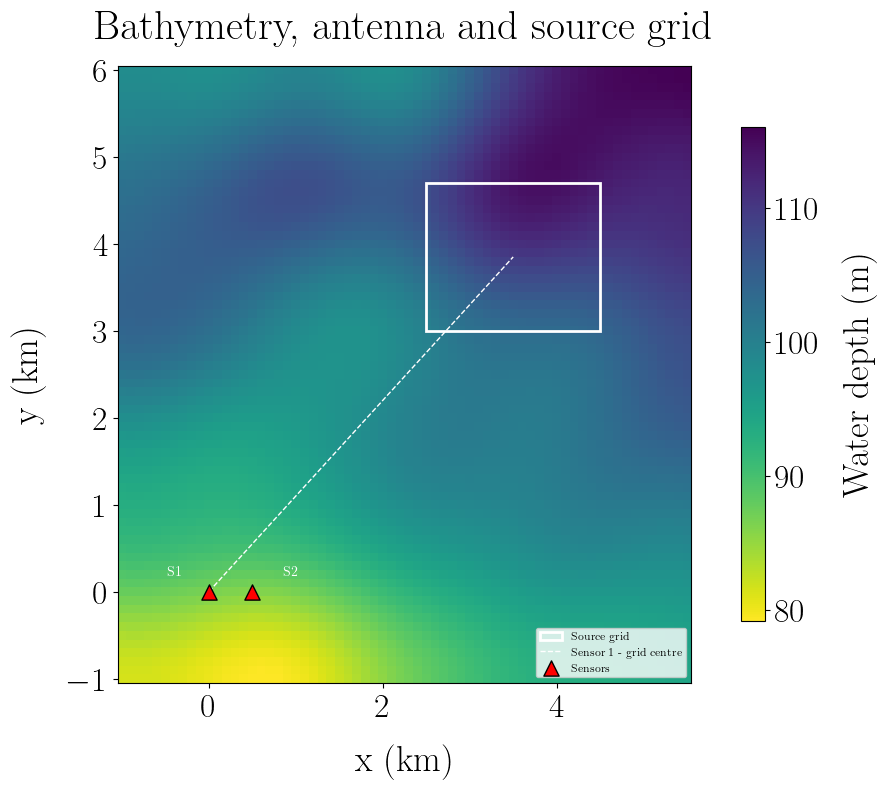

Water depth: mean 100.0 m, min 79.1 m, max 116.0 m
Sensor depths (m): {'S1': 85.6, 'S2': 85.1}


In [251]:
xb, yb, depth = ds["x_bathy"].values, ds["y_bathy"].values, ds["bathymetry"].values

fig, ax = plt.subplots(figsize=(12, 8))
pc = ax.pcolormesh(xb / 1e3, yb / 1e3, depth, cmap="viridis_r", shading="auto")
fig.colorbar(pc, ax=ax, label="Water depth (m)", shrink=0.8)
ax.add_patch(
    plt.Rectangle(
        (x.min() / 1e3, y.min() / 1e3),
        (x.max() - x.min()) / 1e3,
        (y.max() - y.min()) / 1e3,
        fill=False,
        ec="w",
        lw=2,
        label="Source grid",
    )
)
ax.plot(
    [sx[0] / 1e3, x.mean() / 1e3],
    [sy[0] / 1e3, y.mean() / 1e3],
    "w--",
    lw=1,
    label="Sensor 1 - grid centre",
)
ax.scatter(
    sx / 1e3,
    sy / 1e3,
    marker="^",
    c="r",
    s=120,
    edgecolor="k",
    zorder=5,
    label="Sensors",
)
for i, (n, xx, yy) in enumerate(zip(names, sx, sy)):
    ax.annotate(
        n,
        (xx / 1e3, yy / 1e3),
        xytext=(-8 - 22 * (i == 0) + 30 * (i == 1), 12),
        textcoords="offset points",
        color="w",
        weight="bold",
    )
ax.set(
    xlabel="x (km)",
    ylabel="y (km)",
    aspect="equal",
    title="Bathymetry, antenna and source grid",
)
ax.legend(loc="lower right", fontsize=8)
plt.show()

print(
    f"Water depth: mean {depth.mean():.1f} m, min {depth.min():.1f} m, max {depth.max():.1f} m"
)
print("Sensor depths (m):", {n: round(float(z), 1) for n, z in zip(names, sz)})

## Illustration de l'environnement de propagation 

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_24868\4124148571.py:45: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


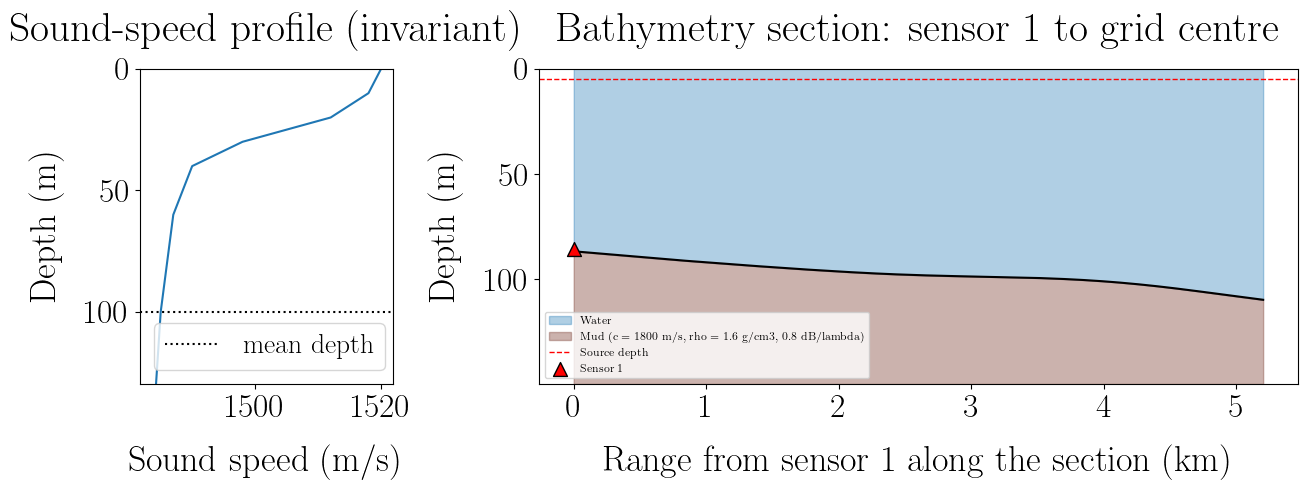

In [252]:
z_ssp, c_ssp = ds["z_ssp"].values, ds["ssp"].values

# Bathymetry section between sensor 1 and the centre of the grid
interp = RegularGridInterpolator((yb, xb), depth)
s = np.linspace(0.0, np.hypot(x.mean() - sx[0], y.mean() - sy[0]), 400)
px, py = sx[0] + s * (x.mean() - sx[0]) / s[-1], sy[0] + s * (y.mean() - sy[0]) / s[-1]
d_section = interp(np.stack([py, px], axis=-1))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 3]}
)
ax1.plot(c_ssp, z_ssp)
ax1.axhline(depth.mean(), color="k", ls=":", label="mean depth")
ax1.set(
    xlabel="Sound speed (m/s)",
    ylabel="Depth (m)",
    title="Sound-speed profile (invariant)",
)
ax1.set_ylim(d_section.max() + 20, 0)
ax1.legend()

zmax = d_section.max() + 40
ax2.fill_between(s / 1e3, 0, d_section, color="tab:blue", alpha=0.35, label="Water")
ax2.fill_between(
    s / 1e3,
    d_section,
    zmax,
    color="tab:brown",
    alpha=0.45,
    label=f"Mud (c = {ds.attrs['sediment_c_p_m_s']:.0f} m/s, rho = {ds.attrs['sediment_rho_g_cm3']:.1f} g/cm3, "
    f"{ds.attrs['sediment_attenuation_dB_per_wavelength']:.1f} dB/lambda)",
)
ax2.plot(s / 1e3, d_section, "k")
ax2.axhline(ds.attrs["source_depth_m"], color="r", ls="--", lw=1, label="Source depth")
ax2.scatter(
    [0], [sz[0]], marker="^", c="r", edgecolor="k", s=100, zorder=5, label="Sensor 1"
)
ax2.set(
    xlabel="Range from sensor 1 along the section (km)",
    ylabel="Depth (m)",
    title="Bathymetry section: sensor 1 to grid centre",
)
ax2.set_ylim(zmax, 0)
ax2.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Transmission loss

`TL = -20 log10 |p|` with `p` the stored pressure. Invalid results (failed KRAKEN/FIELD runs, e.g. below the cutoff frequency) are masked.

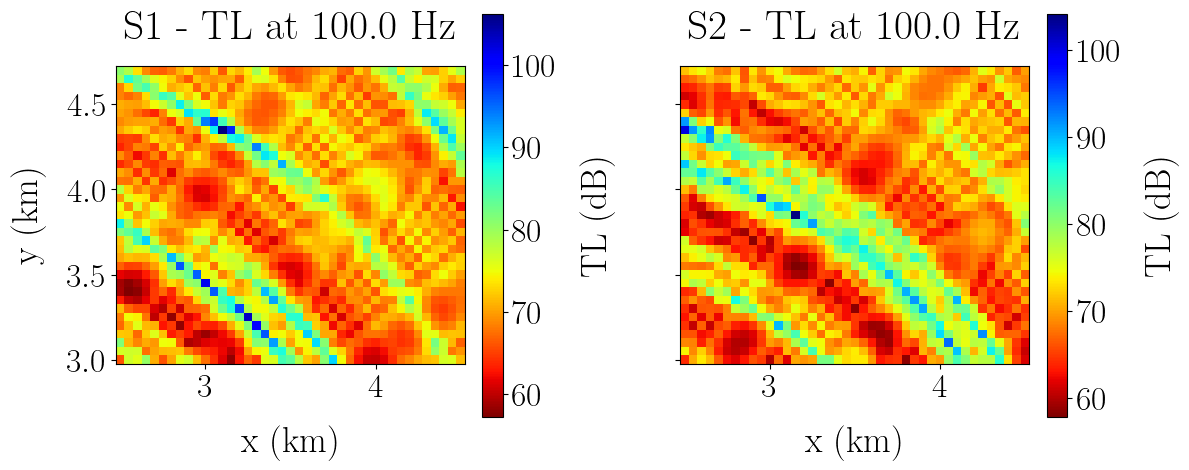

In [253]:
f_plot = 100.0  # Hz
ifreq = int(np.argmin(np.abs(freq - f_plot)))


def tl_db(h, ok):
    tl = -20.0 * np.log10(np.abs(h) + 1e-30)
    return np.where(ok, tl, np.nan)


fig, axs = plt.subplots(
    1,
    len(names),
    figsize=(6 * len(names), 5),
    sharey=True,
    squeeze=False,
    layout="constrained",
)
for i, ax in enumerate(axs[0]):
    tl = tl_db(H[i, ifreq], valid[i, ifreq])
    pc = ax.pcolormesh(x / 1e3, y / 1e3, tl, cmap="jet_r", shading="nearest")
    fig.colorbar(pc, ax=ax, label="TL (dB)")
    ax.set(
        xlabel="x (km)",
        title=f"{names[i]} - TL at {freq[ifreq]:.1f} Hz",
        aspect="equal",
    )
axs[0, 0].set_ylabel("y (km)")
plt.show()

## Position de la source event 

In [254]:
rng = np.random.default_rng(seed=42)
x0, y0 = rng.uniform(x.min(), x.max()), rng.uniform(y.min(), y.max())

## Extraction des grandeurs d'intérêt

In [255]:
# Green's fct on the 2D grid
gf = ds.transfer_function
gf_rcv1 = gf.isel(sensor=0)
gf_rcv2 = gf.isel(sensor=1)

# Pi
pi_21_rr = gf_rcv2 / gf_rcv1
pi_21_r0 = pi_21_rr.sel(x=x0, y=y0, method="nearest")

# Gamma
gamma_21_rr = 20 * np.log10(np.abs(pi_21_rr))
gamma_21_r0 = 20 * np.log10(np.abs(pi_21_r0))

# Intercorr
c21_rr = gf_rcv1 * np.conj(gf_rcv2)
c21_r0 = c21_rr.sel(x=x0, y=y0, method="nearest")

In [256]:
dist_c = np.abs(
    np.nansum(
        c21_r0 * np.conj(c21_rr),
        axis=0,
    )
)
dist_c /= np.max(dist_c)
dist_c = 1 - dist_c

In [257]:
dist_L1 = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L1"
)
dist_L2 = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="L2"
)
# Calc theta with gamma
dist_theta_gamma = calc_gamma_dist(
    gamma_a=gamma_21_r0, gamma_b=gamma_21_rr, dist_type="theta"
)
# With abs(pi)
# dist_theta_gamma = calc_gamma_dist(
#     gamma_a=np.abs(pi_21_r0), gamma_b=np.abs(pi_21_rr), dist_type="theta"
# )

# Calc theta with pi
inner_prod = np.nansum(pi_21_r0 * np.conj(pi_21_rr), axis=0)
norm_a = np.sqrt(np.nansum(pi_21_r0 * np.conj(pi_21_r0), axis=0))
norm_b = np.sqrt(np.nansum(pi_21_rr * np.conj(pi_21_rr), axis=0))
# Clip to [-1, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_theta = 1 - cos_angle  #  to [0, 1]
# dist = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# # # NOTE Should we normalize ? -> for a fair comparison each dist must have the same dynamic range ? 
# dist_L1 /= np.max(dist_L1)
# dist_L2 /= np.max(dist_L2)
# dist_theta /= np.max(dist_theta)
# dist_theta_gamma /= np.max(dist_theta_gamma)

In [258]:
ds_res = xr.Dataset(
    data_vars={
        "dist_L1": (("y", "x"), dist_L1),
        "dist_L2": (("y", "x"), dist_L2),
        "dist_theta": (("y", "x"), dist_theta),
        "dist_theta_gamma": (("y", "x"), dist_theta_gamma),
        "dist_c": (("y", "x"), dist_c),
    },
    coords={"x": x, "y": y},
)

In [259]:
idx = ds_res.dist_theta.argmin(dim=["x", "y"])
xmin, ymin = ds_res.x[idx["x"]].values, ds_res.y[idx["y"]].values
idx_gamma = ds_res.dist_theta_gamma.argmin(dim=["x", "y"])
xmin_gamma, ymin_gamma = ds_res.x[idx_gamma["x"]].values, ds_res.y[idx_gamma["y"]].values
idx_c = ds_res.dist_c.argmin(dim=["x", "y"])
xmin_c, ymin_c = ds_res.x[idx_c["x"]].values, ds_res.y[idx_c["y"]].values

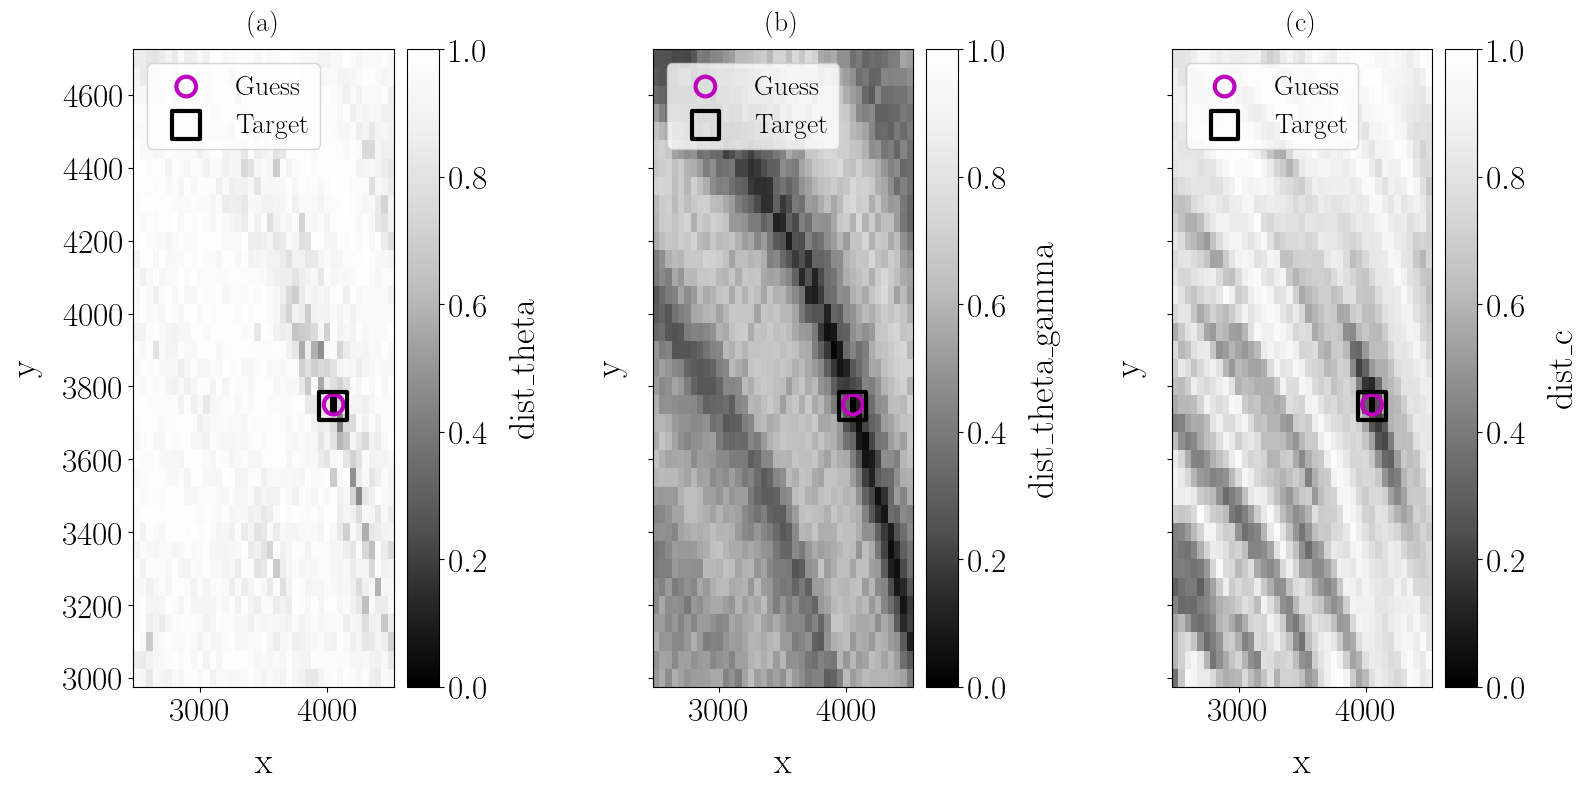

In [260]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 3, figsize=(16, 8), sharex=True, sharey=True)

ds_res.dist_theta.plot(x="x", y="y", cmap=cmap, vmin=0, vmax=1, ax=axs[0])
axs[0].scatter(
    xmin,
    ymin,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

ds_res.dist_theta_gamma.plot(x="x", y="y", cmap=cmap, vmin=0, vmax=1, ax=axs[1])
axs[1].scatter(
    xmin_gamma,
    ymin_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

ds_res.dist_c.plot(x="x", y="y", cmap=cmap, vmin=0, vmax=1, ax=axs[2])
axs[2].scatter(
    xmin_c,
    ymin_c,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)


# axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[0].legend(loc="upper left")


# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2*r0,
#         height=2*r0,
#         angle=0,
#         theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
#         theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--"
#     )

#     ax.add_patch(arc0)

for ax in axs.flatten():
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )
    ax.legend(loc="upper left")

set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

In [261]:
# Reshape to fit original code below
shape_xy_grid = (y.size, x.size)  # (y, x)
shape_2D = (freq.size, y.size * x.size)  # (freq, y*x)
shape_3D = (freq.size, y.size, x.size)  # (freq, y, x)

gamma_21_rr_ = gamma_21_rr.values
gamma_21_rr_ = gamma_21_rr_.reshape(shape_2D)  # Reshape to 2D (freq, y*x)

pi_21_rr_ = pi_21_rr.values
pi_21_rr_ = pi_21_rr_.reshape(shape_2D)  # Reshape to 2D (freq, y*x)

c21_rr_ = c21_rr.values
c21_rr_ = c21_rr_.reshape(
    c21_rr_.shape[0], c21_rr_.shape[1] * c21_rr_.shape[2]
)   # Reshape to 2D (freq, y*x)

In [262]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

# ISOMAP
n_components = 100
n_neighbors = 5
p = 2

# Define isomap object
# With Minkowski distance (equivalent to euclidean distance for p = 2)
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    p=p,
)
# # With cosine distance
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors,
#     n_components=n_components,
#     metric="cosine"
# )

data = gamma_21_rr_.T  # (n_sample, n_features) = (n_pos, nfreq)
# Subsample
# data = data[::2, :]

# Remove nan
idx_f_no_nan = ~np.isnan(data[0, :])
data = data[:, idx_f_no_nan]

# Learn manifold and project data in target dimension

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# RQ : les résultats sont identiques si pas de standardisation des données
# X_scaled = data

# Project
coords = isomap_obj.fit_transform(X_scaled)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_24868\1006218923.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


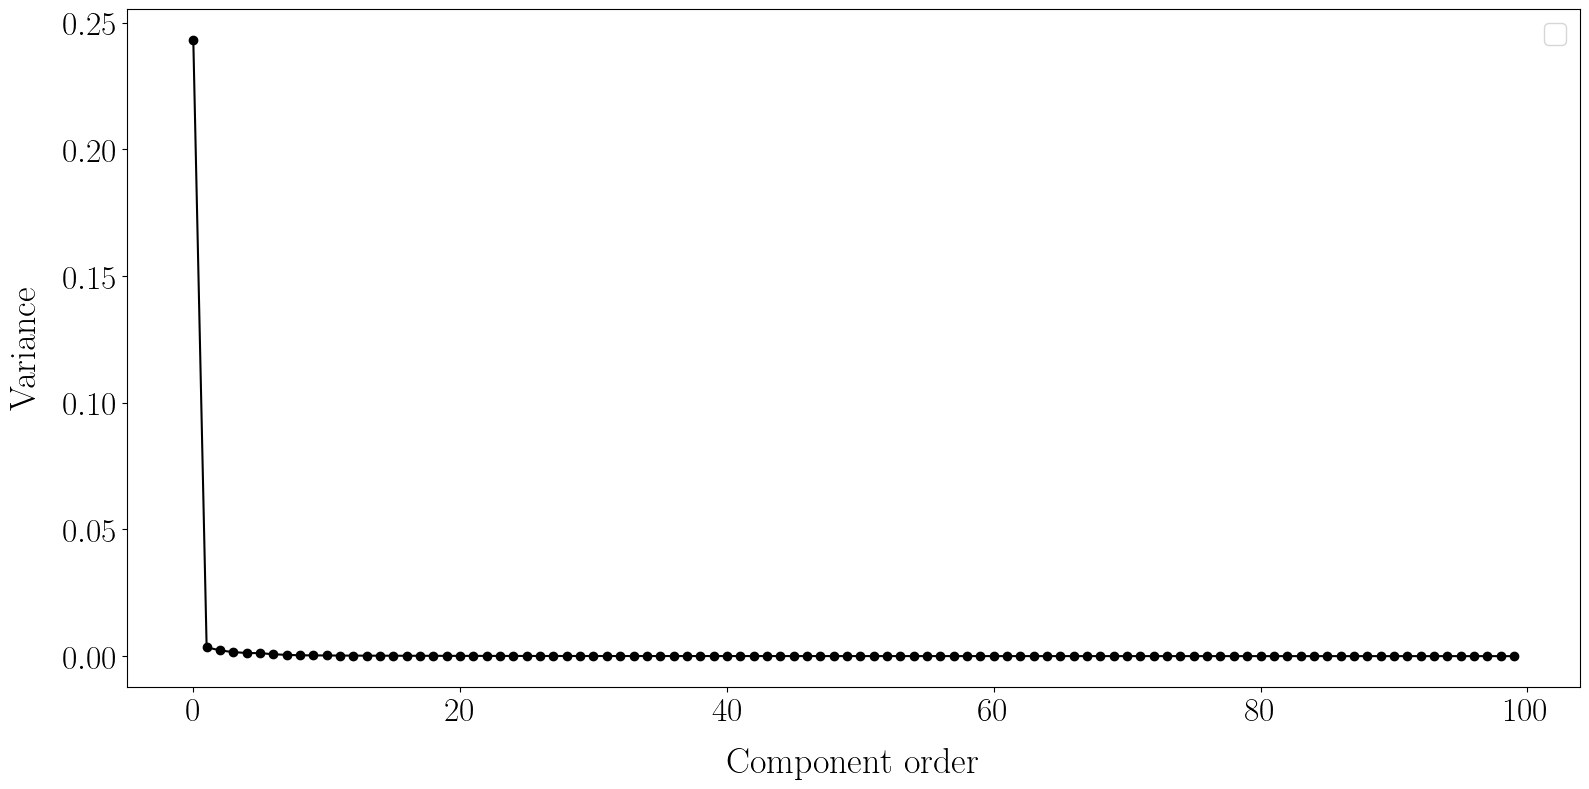

In [263]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_24868\4181134354.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


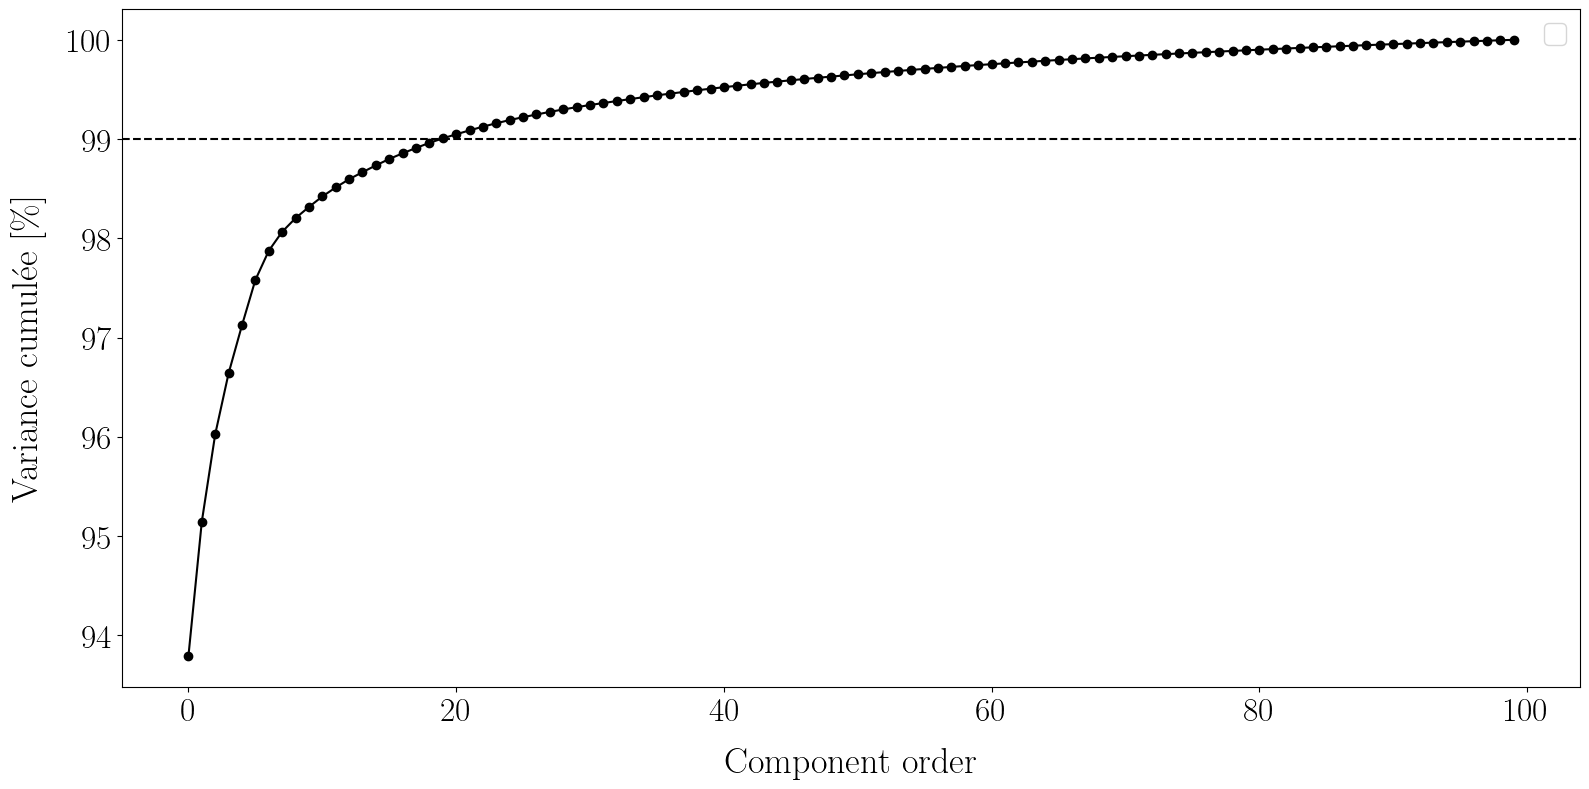

In [264]:
cvar_tot = np.sum(cvar)
cvar_ratio = cvar / cvar_tot
cum_cvar = np.cumsum(cvar_ratio)

# Variance cumulée
cumulative_variance_threshold = 99
plt.figure()
plt.plot(np.arange(cvar.size), cum_cvar * 100, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance cumulée [\%]")
plt.axhline(cumulative_variance_threshold, linestyle="--", color="k")
plt.legend()

In [265]:
# Compute info
cum_cvar_3D = cum_cvar[2]
# Determine the number of components needed to reach the threshold
nb_comp_th = np.argmax(cum_cvar * 100 >= cumulative_variance_threshold) + 1
# Get dimension ratio
dim_ratio = nb_comp_th / data.shape[1]

print(
    f"\tPercentage of explained variance by the first 3 components = {cum_cvar_3D*100:.1f}%"
)
print(
    f"\tNumber of components needed to reach the threshold ({cumulative_variance_threshold} %) = {nb_comp_th:.0f}"
)
print(f"\tDataset reduction of {(1 - dim_ratio)*100:.3f} %")

	Percentage of explained variance by the first 3 components = 96.0%
	Number of components needed to reach the threshold (99 %) = 20
	Dataset reduction of 92.337 %


### Allure des composantes 

In [266]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr_.T  # (n_sample, n_features) = (n_pos, nfreq)

# Subsample
# gamma_ = gamma_[::10, :]

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# ### RTF (Pi) ###
# Learn manifold and project data in target dimension
pi_21_ = pi_21_rr_.T  # (n_pos, nfreq)

# Calc theta with pi
inner_prod = np.nansum(
    pi_21_[np.newaxis, :, :] * np.conj(pi_21_)[:, np.newaxis, :], axis=-1
)
norm_a = np.sqrt(
    np.nansum(pi_21_[np.newaxis, :, :] * np.conj(pi_21_)[np.newaxis, :, :], axis=-1)
)
norm_b = np.sqrt(
    np.nansum(pi_21_[:, np.newaxis, :] * np.conj(pi_21_)[:, np.newaxis, :], axis=-1)
)
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

### DCF ###
c12_ = c21_rr_.T
# Subsample to reduce memory
# c12_ = c12_[::2, :]
dist_mat = np.abs(
    np.nansum(
        c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
        axis=-1,
    )
)
dist_mat = dist_mat / np.max(dist_mat)
dist_mat_dcf = 1 - dist_mat

In [267]:
gamma_.shape, freq.size, 

((1435, 261), 261)

In [268]:
dist_mat_rtf_gamma.shape, dist_mat_rtf_pi.shape, dist_mat_dcf.shape

((1435, 1435), (1435, 1435), (1435, 1435))

In [269]:
n_components = 8
n_neighbors = 10
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# ### RTF (Pi) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isompa_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
coords_isompa_pi = coords_isompa_pi / np.max(np.abs(coords_isompa_pi))

# ### DCF ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isompa_dcf = isomap_obj.fit_transform(dist_mat_dcf)
coords_isompa_dcf = coords_isompa_dcf / np.max(np.abs(coords_isompa_dcf))

In [270]:
coords_isomap_gamma.shape, coords_isompa_pi.shape, coords_isompa_dcf.shape

((1435, 8), (1435, 8), (1435, 8))

In [271]:
# Reshape coords to 2D grid shape (y, x, n_components)
shape = (y.size, x.size, n_components)
coords_isomap_gamma = coords_isomap_gamma.reshape(shape)
coords_isompa_pi = coords_isompa_pi.reshape(shape)
coords_isompa_dcf = coords_isompa_dcf.reshape(shape)

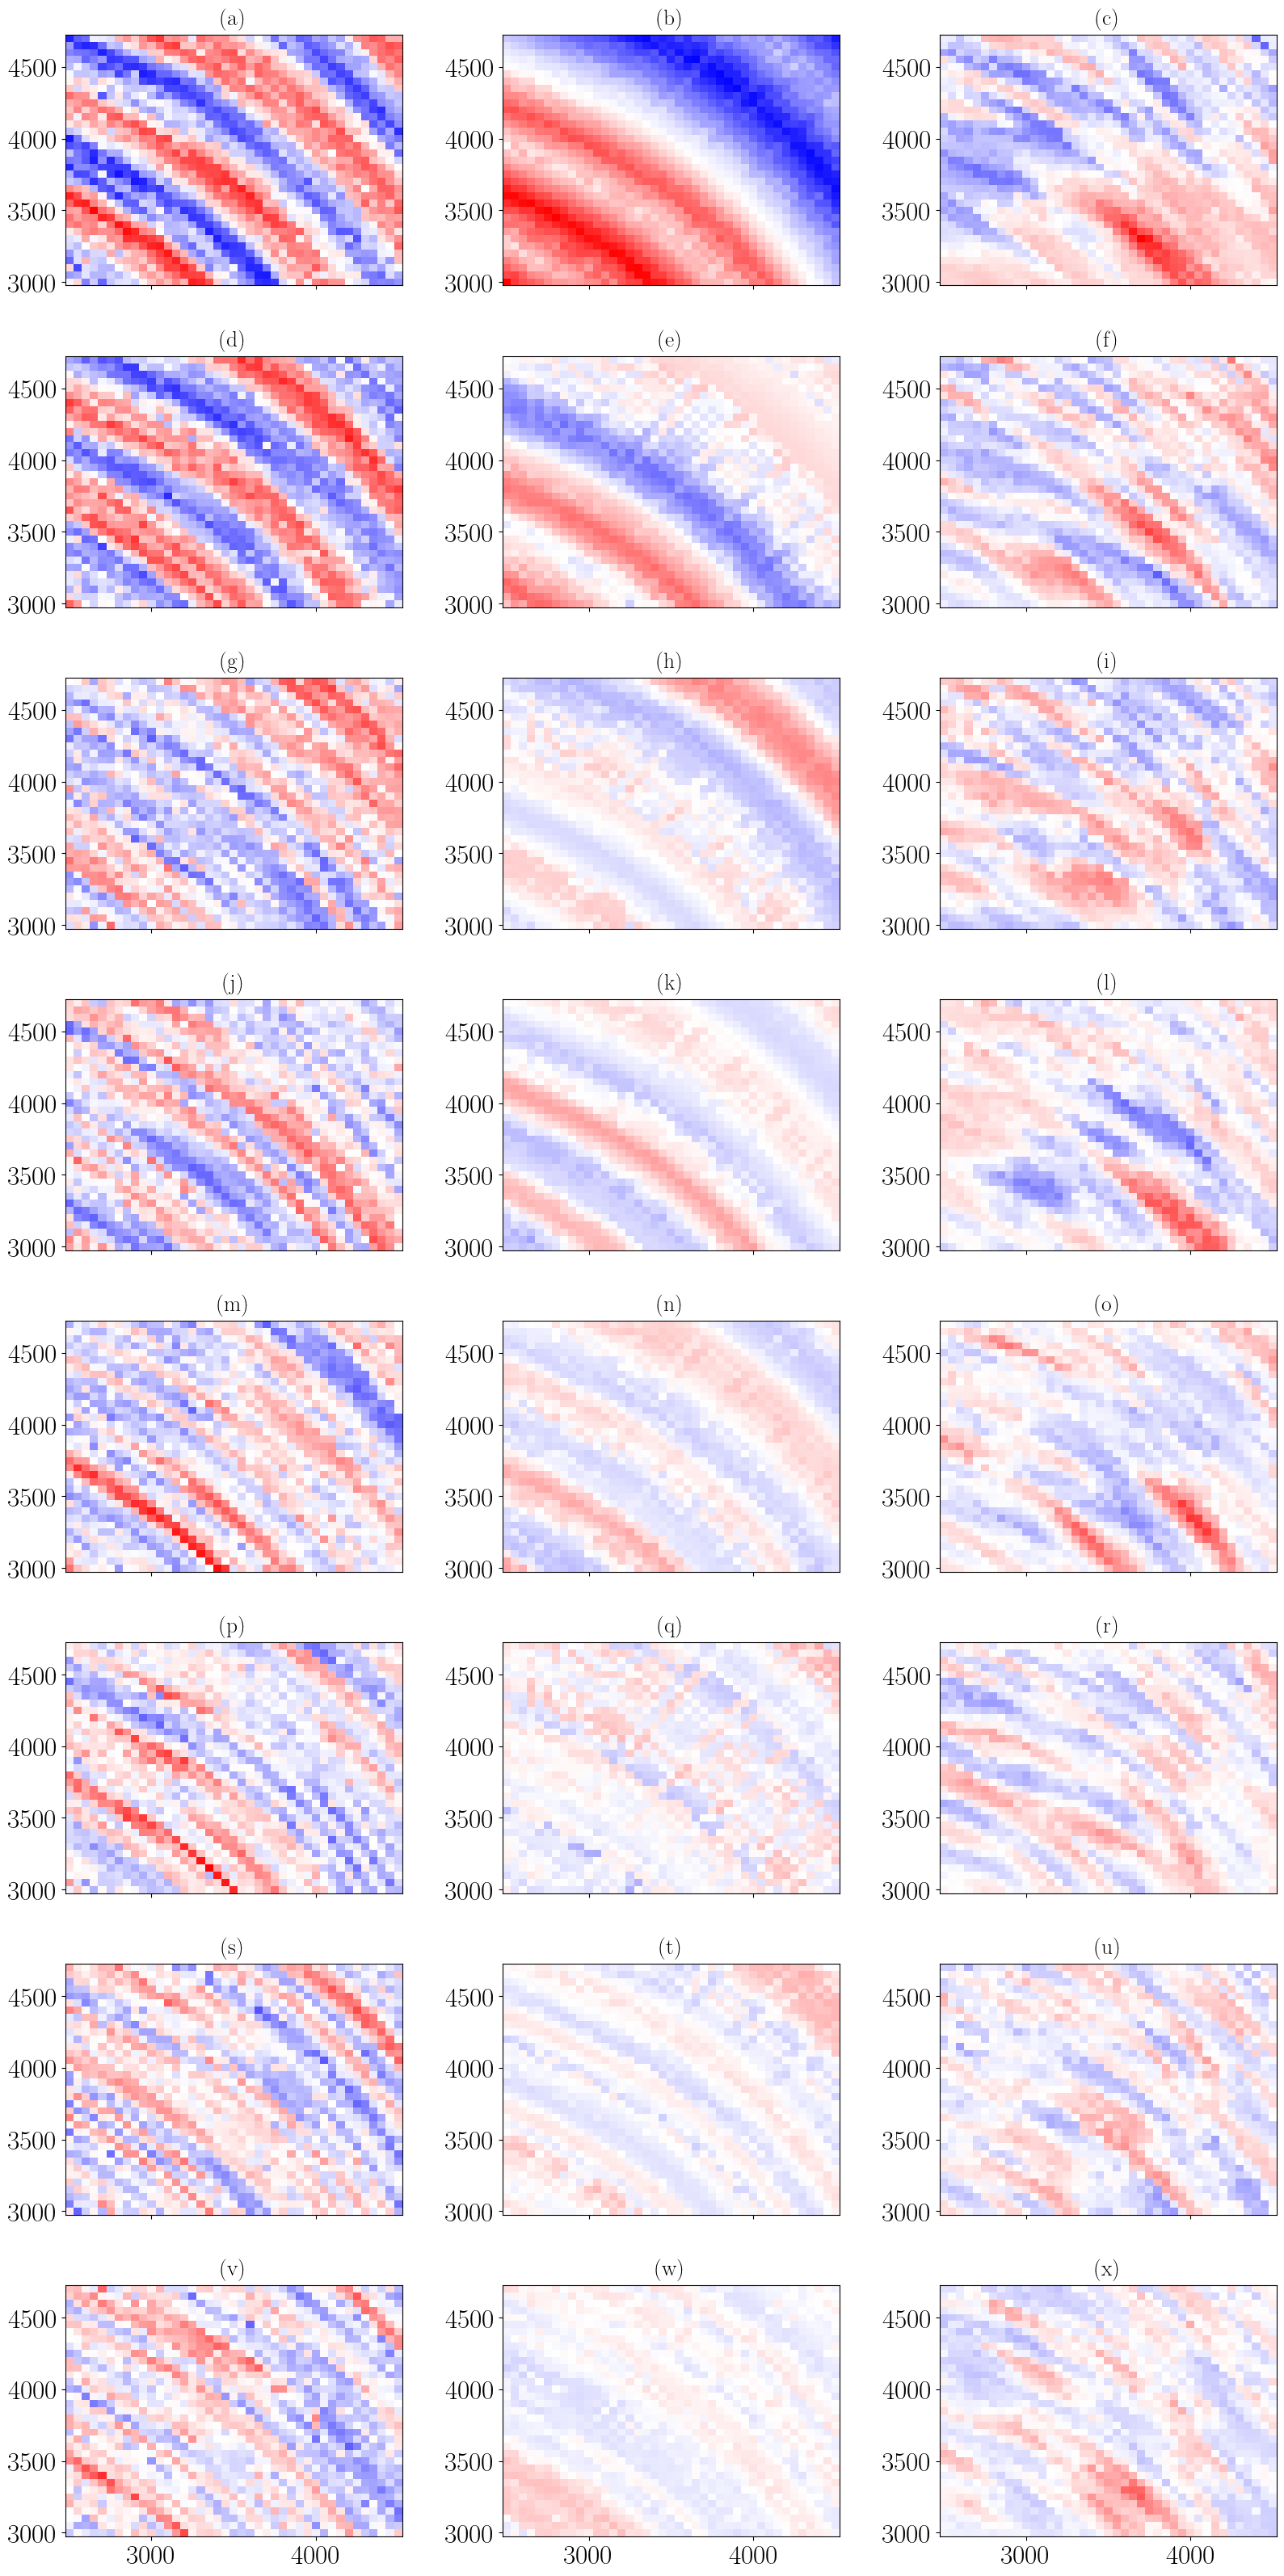

In [272]:
fig, axs = plt.subplots(n_components, 3, figsize=(16, 4*n_components), sharex=True)
# axs = axs.flatten()
for i in range(n_components):
    axs[i, 0].pcolormesh(x, y, coords_isompa_pi[..., i], cmap="bwr", vmin=-1, vmax=1)
    axs[i, 1].pcolormesh(x, y, coords_isomap_gamma[..., i], cmap="bwr", vmin=-1, vmax=1)
    axs[i, 2].pcolormesh(x, y, coords_isompa_dcf[..., i], cmap="bwr", vmin=-1, vmax=1)


# for ax in axs.flatten():
#     ax.scatter(x_rcv1, y_rcv1, label="RCV1")
#     ax.scatter(x_rcv2, y_rcv2, label="RCV2")
#     ax.scatter(
#         x0,
#         y0,
#         marker="s",
#         s=400,
#         facecolors="none",
#         edgecolors="k",
#         label="Target",
#         linewidth=3,
#     )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# -------------------------------------------------------
# Add circles corresponding to r = r10 and r = r20
# -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

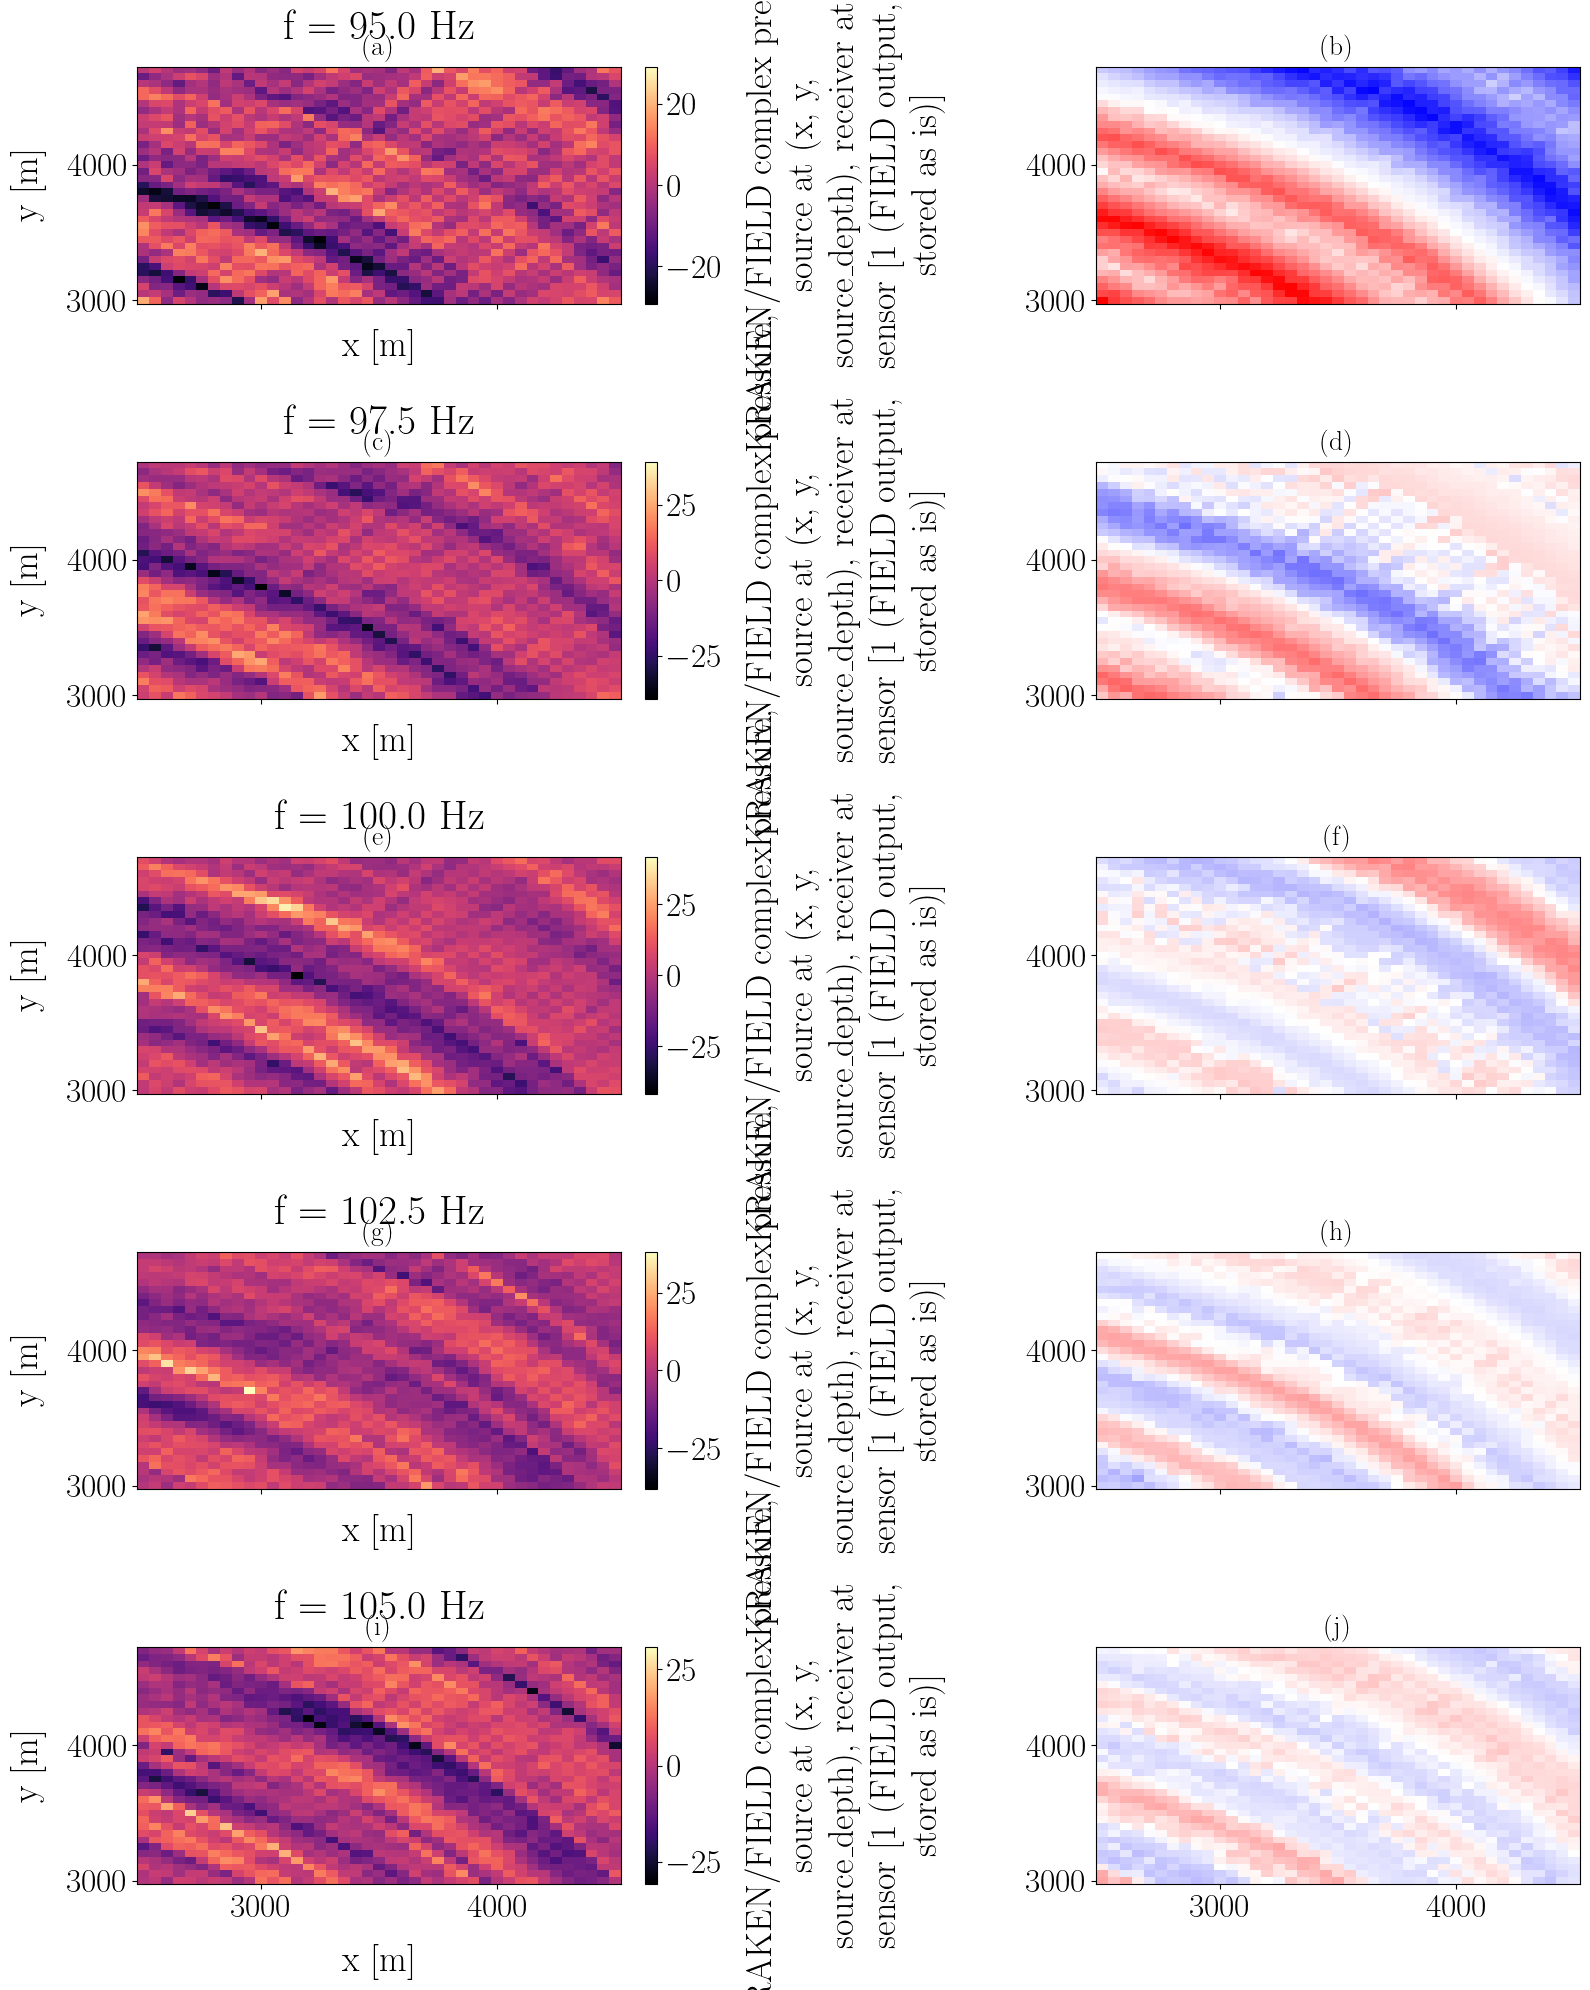

In [273]:
freq_plot = [95, 97.5, 100, 102.5, 105]
fig, axs = plt.subplots(len(freq_plot), 2, figsize=(16, 4 * len(freq_plot)), sharex=True)
# axs = axs.flatten()
for i in range(len(freq_plot)):
    idx_f = np.argmin(np.abs(freq-freq_plot[i]))
    gamma_21_rr.sel(freq=freq[idx_f]).plot(x="x", y="y", cmap="magma", ax=axs[i, 0])
    # axs[i, 0].pcolormesh(x, y, gamma_21_rr_grid[..., idx_f], cmap="magma")
    axs[i, 0].set_title(f"f = {freq[idx_f]} Hz")
    axs[i, 1].pcolormesh(x, y, coords_isomap_gamma[..., i], cmap="bwr", vmin=-1, vmax=1)


# for ax in axs.flatten():
#     ax.scatter(x_rcv1, y_rcv1, label="RCV1")
#     ax.scatter(x_rcv2, y_rcv2, label="RCV2")
#     ax.scatter(
#         x0,
#         y0,
#         marker="s",
#         s=400,
#         facecolors="none",
#         edgecolors="k",
#         label="Target",
#         linewidth=3,
#     )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# # plt.colorbar(im)

# -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

# Interpolation par apprentissage de variété 

## Génération d'un jeu de données éparse pour la librarie 

In [ ]:
from illustration.mfp.mfp_measured.mfp_processor_and_grid_resolution import generate_ship_tracks

In [444]:
def get_features_along_tracks(x_tracks, y_tracks, pi_21_rr, gamma_21_rr, c21_rr):
    pi_along_track = []
    gamma_along_track = []
    c21_along_track = []
    ntracks = len(x_tracks)
    for itrack in range(ntracks):
        xt = x_tracks[itrack]
        yt = y_tracks[itrack]

        pi_along_track.append(
            np.vstack(
                [
                    pi_21_rr.sel(x=xt[i], y=yt[i], method="nearest").values
                    for i in range(yt.size)
                ]
            )
        )

        gamma_along_track.append(
            np.vstack(
                [
                    gamma_21_rr.sel(x=xt[i], y=yt[i], method="nearest").values
                    for i in range(yt.size)
                ]
            )
        )

        c21_along_track.append(
            np.vstack(
                [
                    c21_rr.sel(x=xt[i], y=yt[i], method="nearest").values
                    for i in range(yt.size)
                ]
            )
        )

    pi_along_track = np.concat(pi_along_track)
    pi_21_rr_sparse = pi_along_track.T
    gamma_along_track = np.concat(gamma_along_track)
    gamma_21_rr_sparse = gamma_along_track.T
    c21_along_track = np.concat(c21_along_track)
    c21_rr_sparse = c21_along_track.T

    return pi_21_rr_sparse, gamma_21_rr_sparse, c21_rr_sparse

### Test calibration de la méthode d'échantillonnage 

On prend une trajectoire et on compare les grandeurs signantes relevées le long de la trajectoire à la donnée d'origine

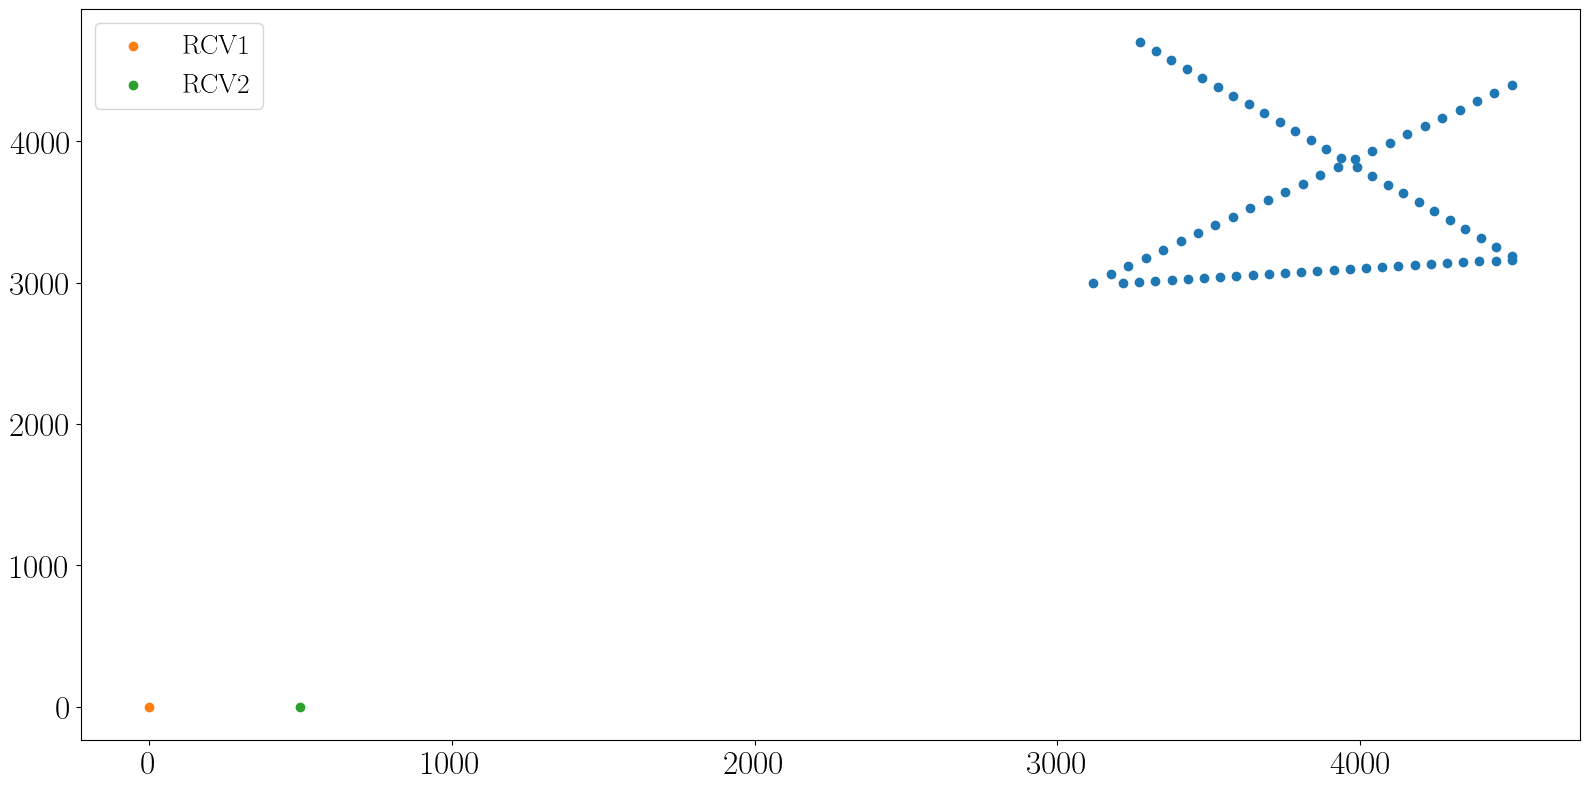

In [467]:
# ntracks = 5
random_seed = 41
x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=3, npt=25, random_seed=random_seed)      # OK pour 15

x_lib_sparse = np.concat(x_tracks)
y_lib_sparse = np.concat(y_tracks)
ntracks = len(x_tracks)

plt.scatter(
    x_lib_sparse,
    y_lib_sparse,
)
plt.scatter(
    x_rcv1,
    y_rcv1,
    label="RCV1",
)
plt.scatter(
    x_rcv2,
    y_rcv2,
    label="RCV2",
)
plt.legend()

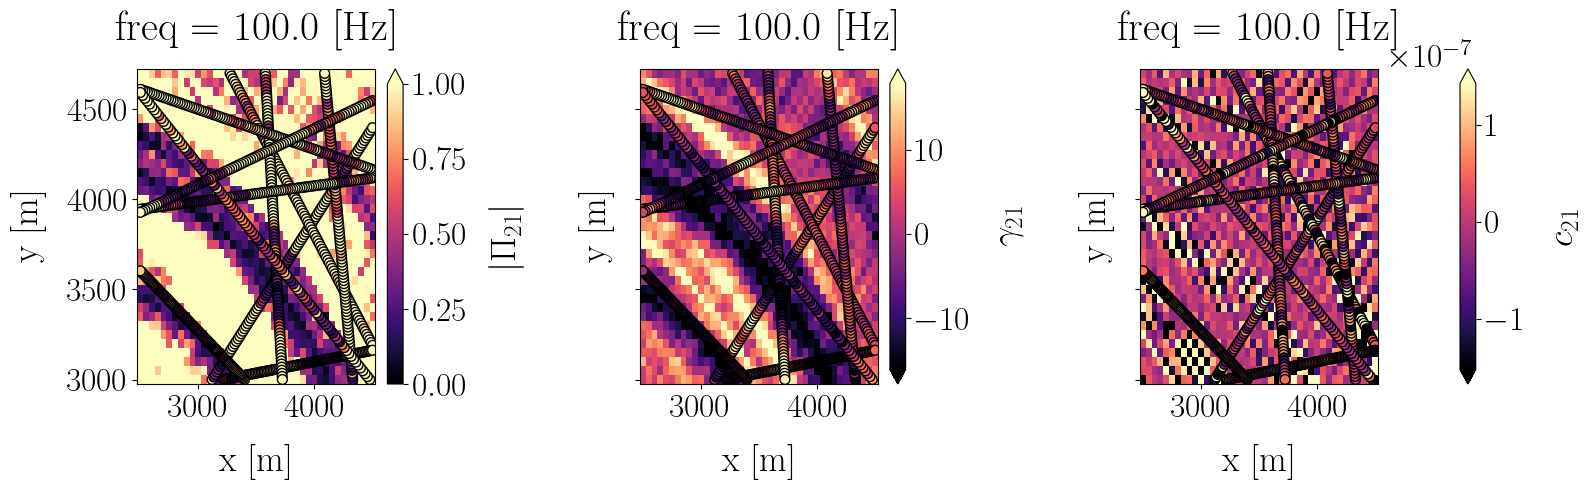

In [496]:
pi_21_rr_sparse, gamma_21_rr_sparse, c21_rr_sparse = get_features_along_tracks(
    x_tracks, y_tracks, pi_21_rr, gamma_21_rr, c21_rr
)
pi_21_rr_sparse.shape, freq.size, x_lib_sparse.shape

fplot = 100
ifreq = np.argmin(np.abs(freq - fplot))
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
np.abs(pi_21_rr).sel(freq=fplot).plot(
    x="x",
    y="y",
    cmap="magma",
    vmin=0,
    vmax=1,
    ax=axs[0],
    cbar_kwargs={"label": r"$\lvert \Pi_{21} \rvert$"},
)
axs[0].scatter(
    x_lib_sparse,
    y_lib_sparse,
    c=np.abs(pi_21_rr_sparse)[ifreq, :],
    cmap="magma",
    vmin=0,
    vmax=1,
    s=50,
    edgecolors="k",
)

vmin = np.percentile(gamma_21_rr.sel(freq=fplot).values, 5)
vmax = np.percentile(gamma_21_rr.sel(freq=fplot).values, 95)
gamma_21_rr.sel(freq=fplot).plot(
    x="x",
    y="y",
    cmap="magma",
    vmin=vmin,
    vmax=vmax,
    ax=axs[1],
    cbar_kwargs={"label": r"$\gamma_{21}$"},
)
axs[1].scatter(
    x_lib_sparse,
    y_lib_sparse,
    c=gamma_21_rr_sparse[ifreq, :],
    cmap="magma",
    vmin=vmin,
    vmax=vmax,
    s=50,
    edgecolors="k"
)

vmin = np.percentile(np.real(c21_rr.sel(freq=fplot)).values, 5)
vmax = np.percentile(np.real(c21_rr.sel(freq=fplot)).values, 95)
np.real(c21_rr.sel(freq=fplot)).plot(
    x="x",
    y="y",
    cmap="magma",
    vmin=vmin,
    vmax=vmax,
    ax=axs[2],
    cbar_kwargs={"label": r"$c_{21}$"},
)
axs[2].scatter(
    x_lib_sparse,
    y_lib_sparse,
    c=np.real(c21_rr_sparse[ifreq, :]),
    cmap="magma",
    vmin=vmin,
    vmax=vmax,
    s=50,
    edgecolors="k",
)

Ok, les points coïncident avec la donnée d'origine. 

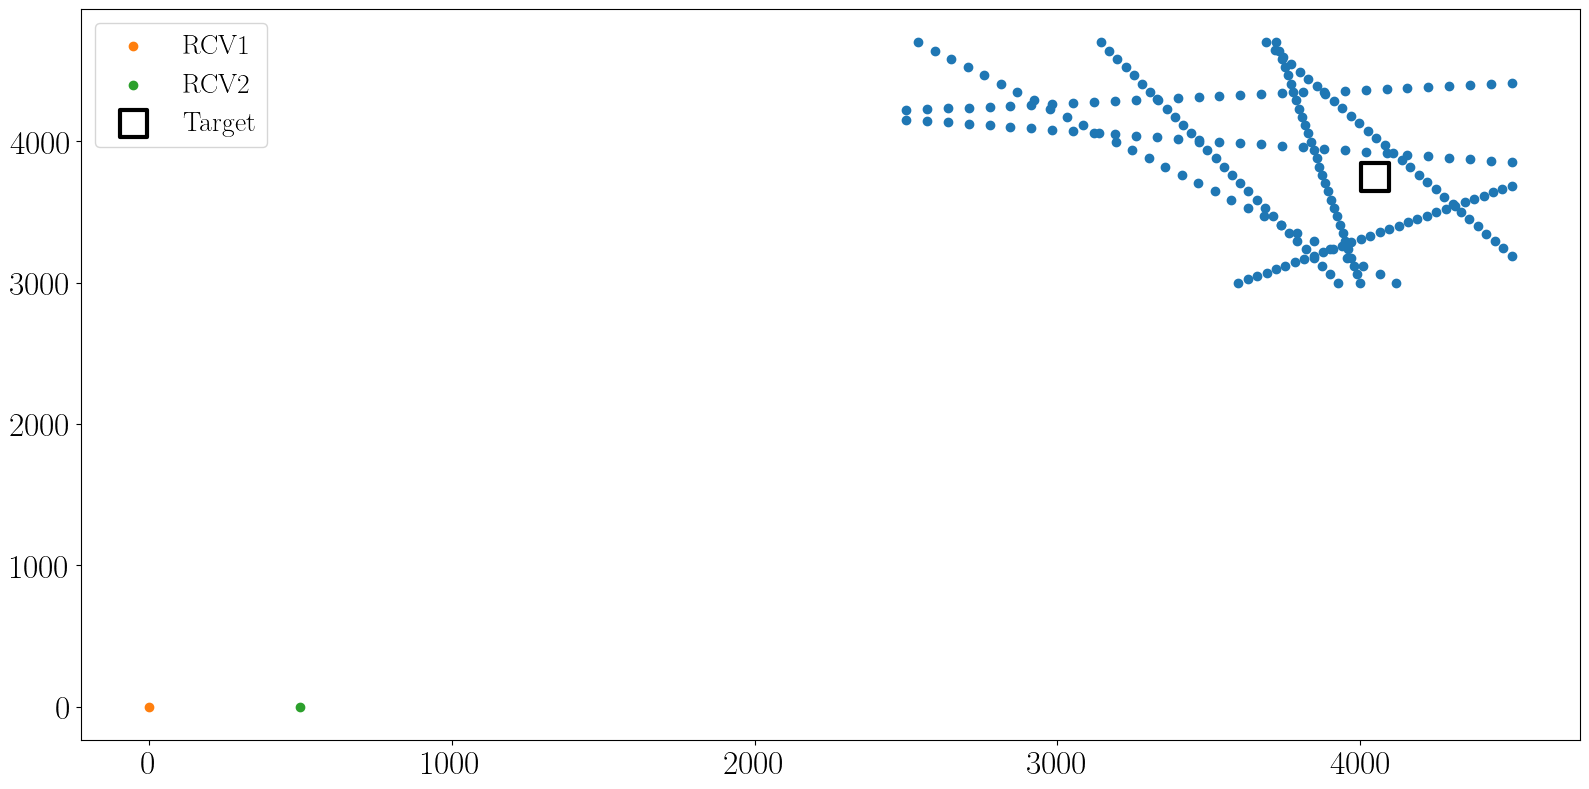

In [666]:
# ntracks = 5
random_seed = 4
x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=7, npt=30, random_seed=random_seed)      # OK pour 15
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=10, npt=100, random_seed=random_seed)        # Ok pour 10
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=100, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=200, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5
x_lib_sparse = np.concat(x_tracks)
y_lib_sparse = np.concat(y_tracks)
ntracks = len(x_tracks)

plt.scatter(
    x_lib_sparse,
    y_lib_sparse,
)
plt.scatter(
    x_rcv1,
    y_rcv1,
    label="RCV1",
)
plt.scatter(
    x_rcv2,
    y_rcv2,
    label="RCV2",
)
plt.scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
plt.legend()

## RTF le long des trajectoires 

In [667]:
pi_21_rr_sparse, gamma_21_rr_sparse, c21_rr_sparse = get_features_along_tracks(x_tracks, y_tracks, pi_21_rr, gamma_21_rr, c21_rr)

## Apprentissage de variété 

In [668]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr_sparse.T  # (n_sample, n_features) = (n_pos, nfreq)

# Subsample
# gamma_ = gamma_[::10, :]

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# ### RTF (Pi) ###
# Learn manifold and project data in target dimension
pi_21_rr_ = pi_21_rr_sparse.T  # (n_pos, nfreq)

# Calc theta with pi
inner_prod = np.nansum(
    pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
)
norm_a = np.sqrt(
    np.nansum(
        pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[np.newaxis, :, :], axis=-1
    )
)
norm_b = np.sqrt(
    np.nansum(
        pi_21_rr_[:, np.newaxis, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
    )
)
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

### DCF ###
c12_ = c21_rr_sparse.T
# Subsample to reduce memory
# c12_ = c12_[::2, :]
dist_mat = np.abs(
    np.nansum(
        c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
        axis=-1,
    )
)
dist_mat = dist_mat / np.max(dist_mat)
dist_mat_dcf = 1 - dist_mat

In [669]:
n_components = 25
n_neighbors = 25
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# ### RTF (Pi) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
coords_isomap_pi = coords_isomap_pi / np.max(np.abs(coords_isomap_pi))

# ### DCF ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_dcf = isomap_obj.fit_transform(dist_mat_dcf)
coords_isomap_dcf = coords_isomap_dcf / np.max(np.abs(coords_isomap_dcf))

In [670]:
coords_isomap_dcf.shape

(210, 25)

In [671]:
# # Reshape coords to 2D grid
# shape = (x_lib_sparse.size, y_lib_sparse.size, n_components)
# coords_isomap_gamma = coords_isomap_gamma.reshape(shape)
# coords_isomap_pi = coords_isomap_pi.reshape(shape)
# coords_isomap_dcf = coords_isomap_dcf.reshape(shape)

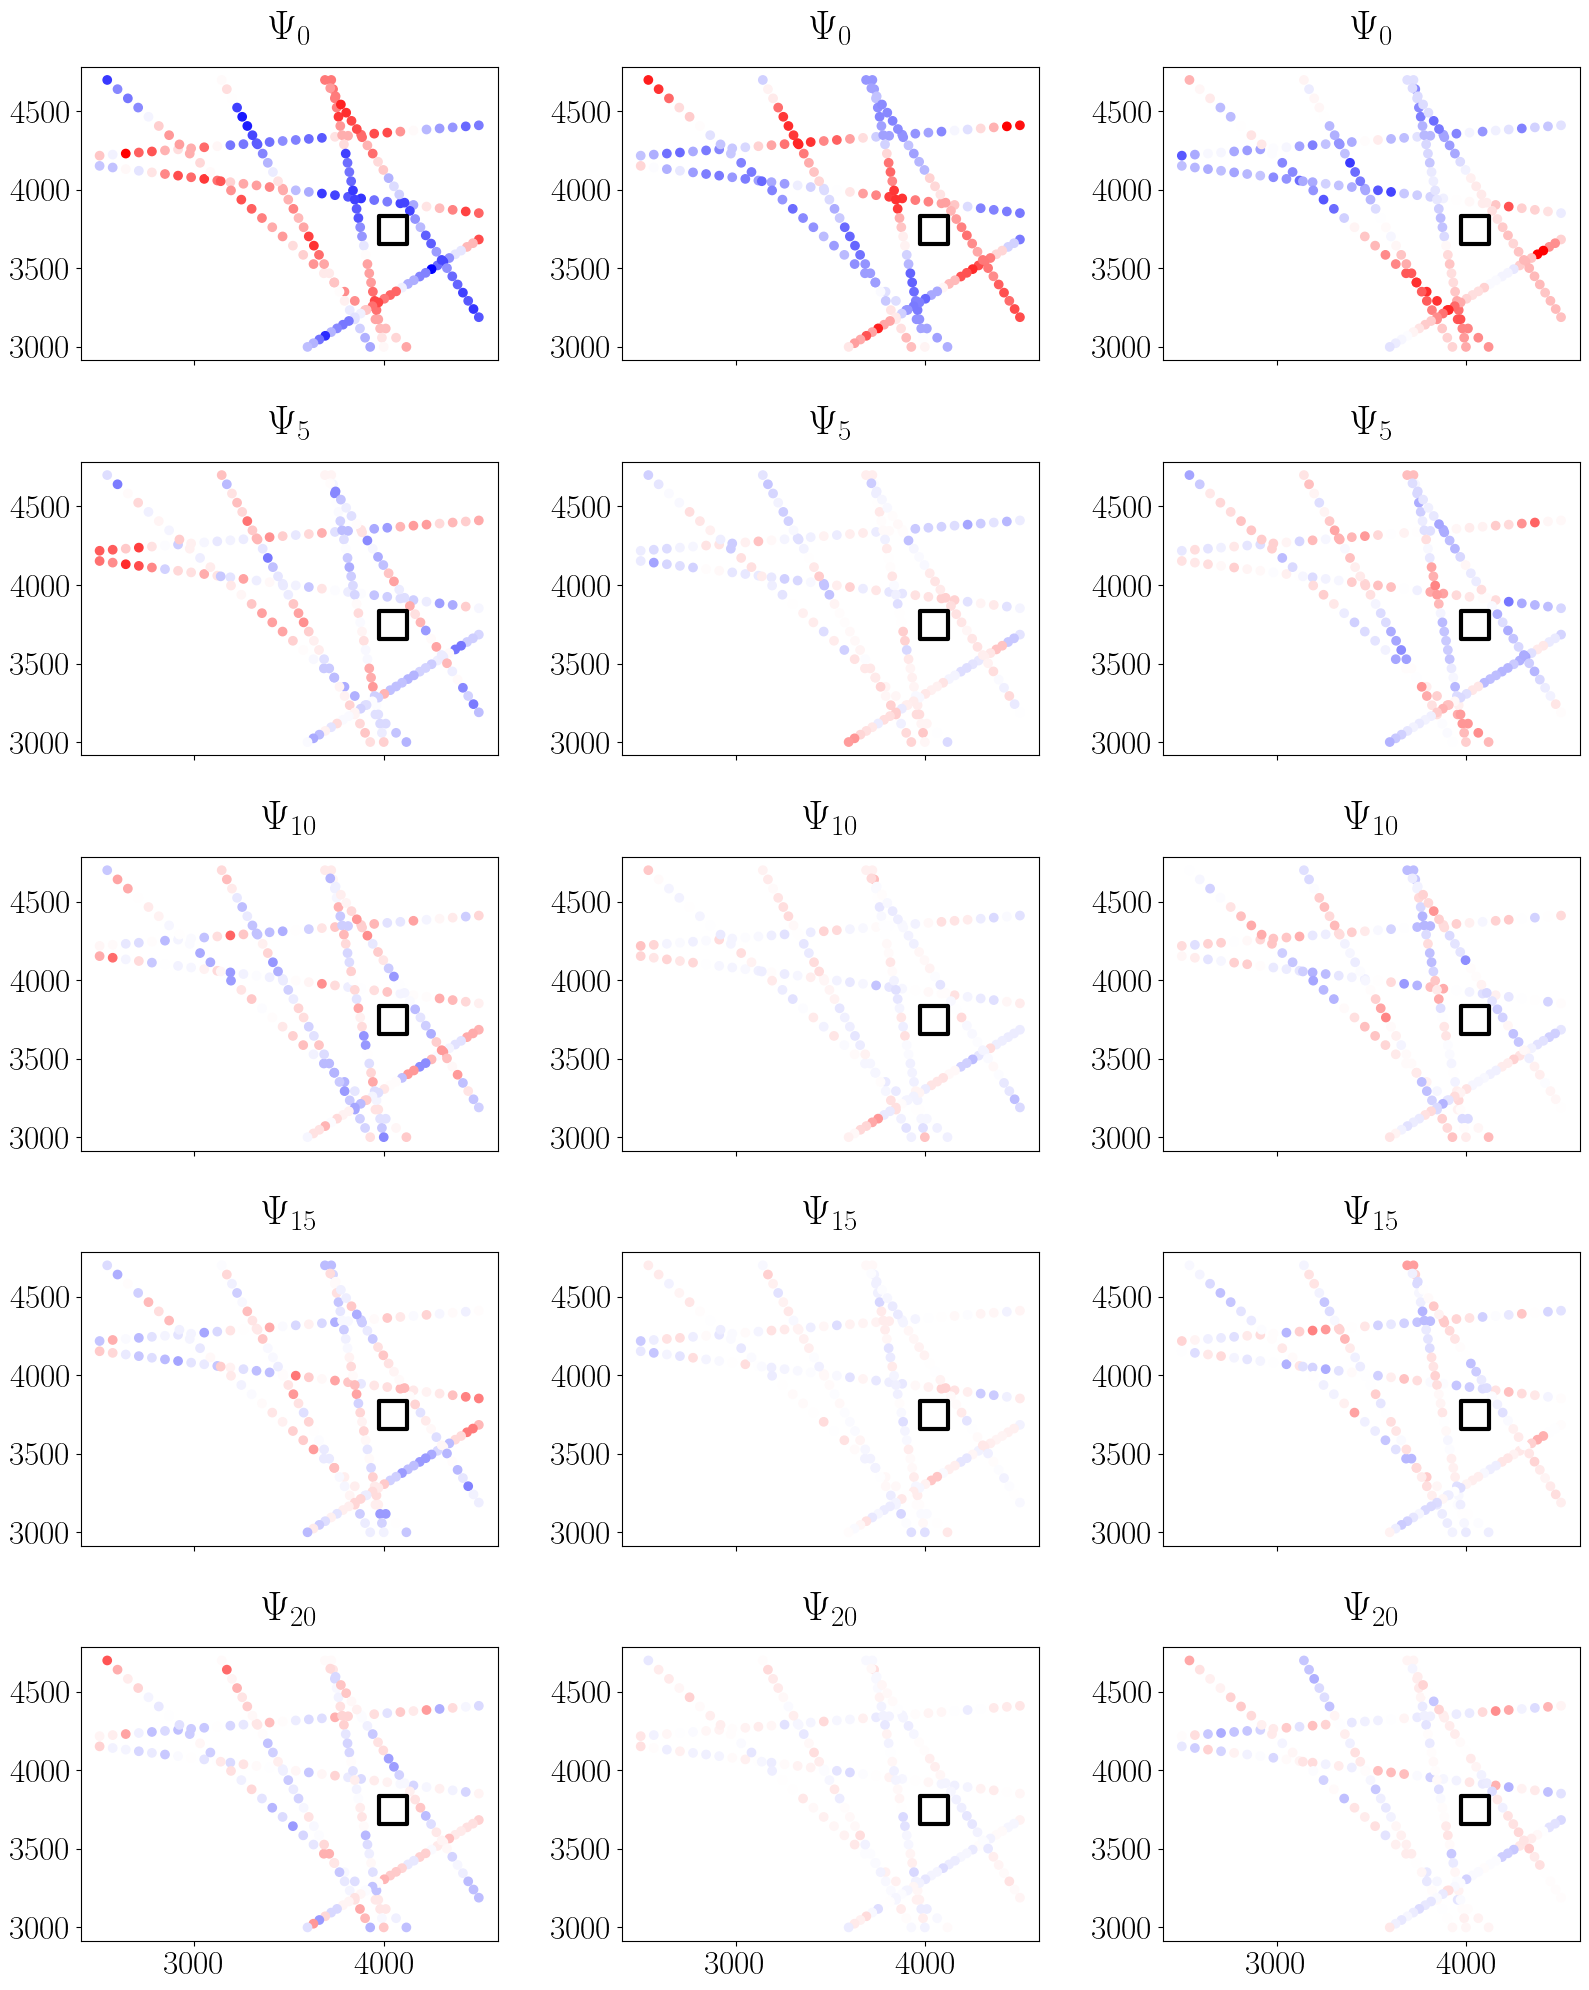

In [672]:
# axs = axs.flatten()
if n_components <= 5:
    comp_to_plot = np.arange(n_components)
else:
    comp_to_plot = np.linspace(0, n_components, num=5, endpoint=False).astype(int)

ncomp = comp_to_plot.size 

fig, axs = plt.subplots(ncomp, 3, figsize=(16, 4*ncomp), sharex=True)
for i, icomp in enumerate(comp_to_plot):
    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_pi[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    axs[i, 1].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_gamma[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    axs[i, 2].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_dcf[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )

    axs[i, 0].set_title(rf"$\Psi_{{{icomp}}}$")
    axs[i, 1].set_title(rf"$\Psi_{{{icomp}}}$")
    axs[i, 2].set_title(rf"$\Psi_{{{icomp}}}$")


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

## Interpolation des coordonnées en projection 

In [673]:
xx, yy = np.meshgrid(ds.x.values, ds.y.values)
xx_flat = xx.flatten()
yy_flat = yy.flatten()

dx_grid_lib = xx_flat[:, np.newaxis] - x_lib_sparse[np.newaxis, :]  # (n_xx, n_xlib)
dy_grid_lib = yy_flat[:, np.newaxis] - y_lib_sparse[np.newaxis, :]  # (n_yy, n_ylib)
r_grid_lib = np.sqrt(dx_grid_lib**2 + dy_grid_lib**2)
r_grid_lib.shape

# # check this is okay
# i, j = -1, -1
# print(
#     f"Distance from grid point of coords e={xx_flat[i]}, n={yy_flat[i]} : {r_grid_lib[i, :]}"
# )
# # Non vectorized calc for comparison
# x_test = xx_flat[i]
# y_test = yy_flat[i]
# r_test = np.sqrt((x_test - x_lib_sparse) ** 2 + (y_test - y_lib_sparse) ** 2)
# print(np.allclose(r_test, r_grid_lib[i, :]))

(1435, 210)

In [674]:
# Interpolate each coords in low dim
i = 0
power = 10

low_dim = 15
coords_low_dim = coords_isomap_gamma[:, :low_dim]
coords_low_dim_grid = np.empty((xx_flat.shape[0], coords_low_dim.shape[1]))
for i in range(low_dim):
    psi_i = coords_low_dim[:, i]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(psi_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    psi_i_interp = numerator / weights

    coords_low_dim_grid[:, i] = psi_i_interp

# Reshape
coords_low_dim_grid = np.reshape(
    coords_low_dim_grid, xx.shape + (coords_low_dim_grid.shape[1],)
)

In [675]:
comp_to_plot

array([ 0,  5, 10, 15, 20])

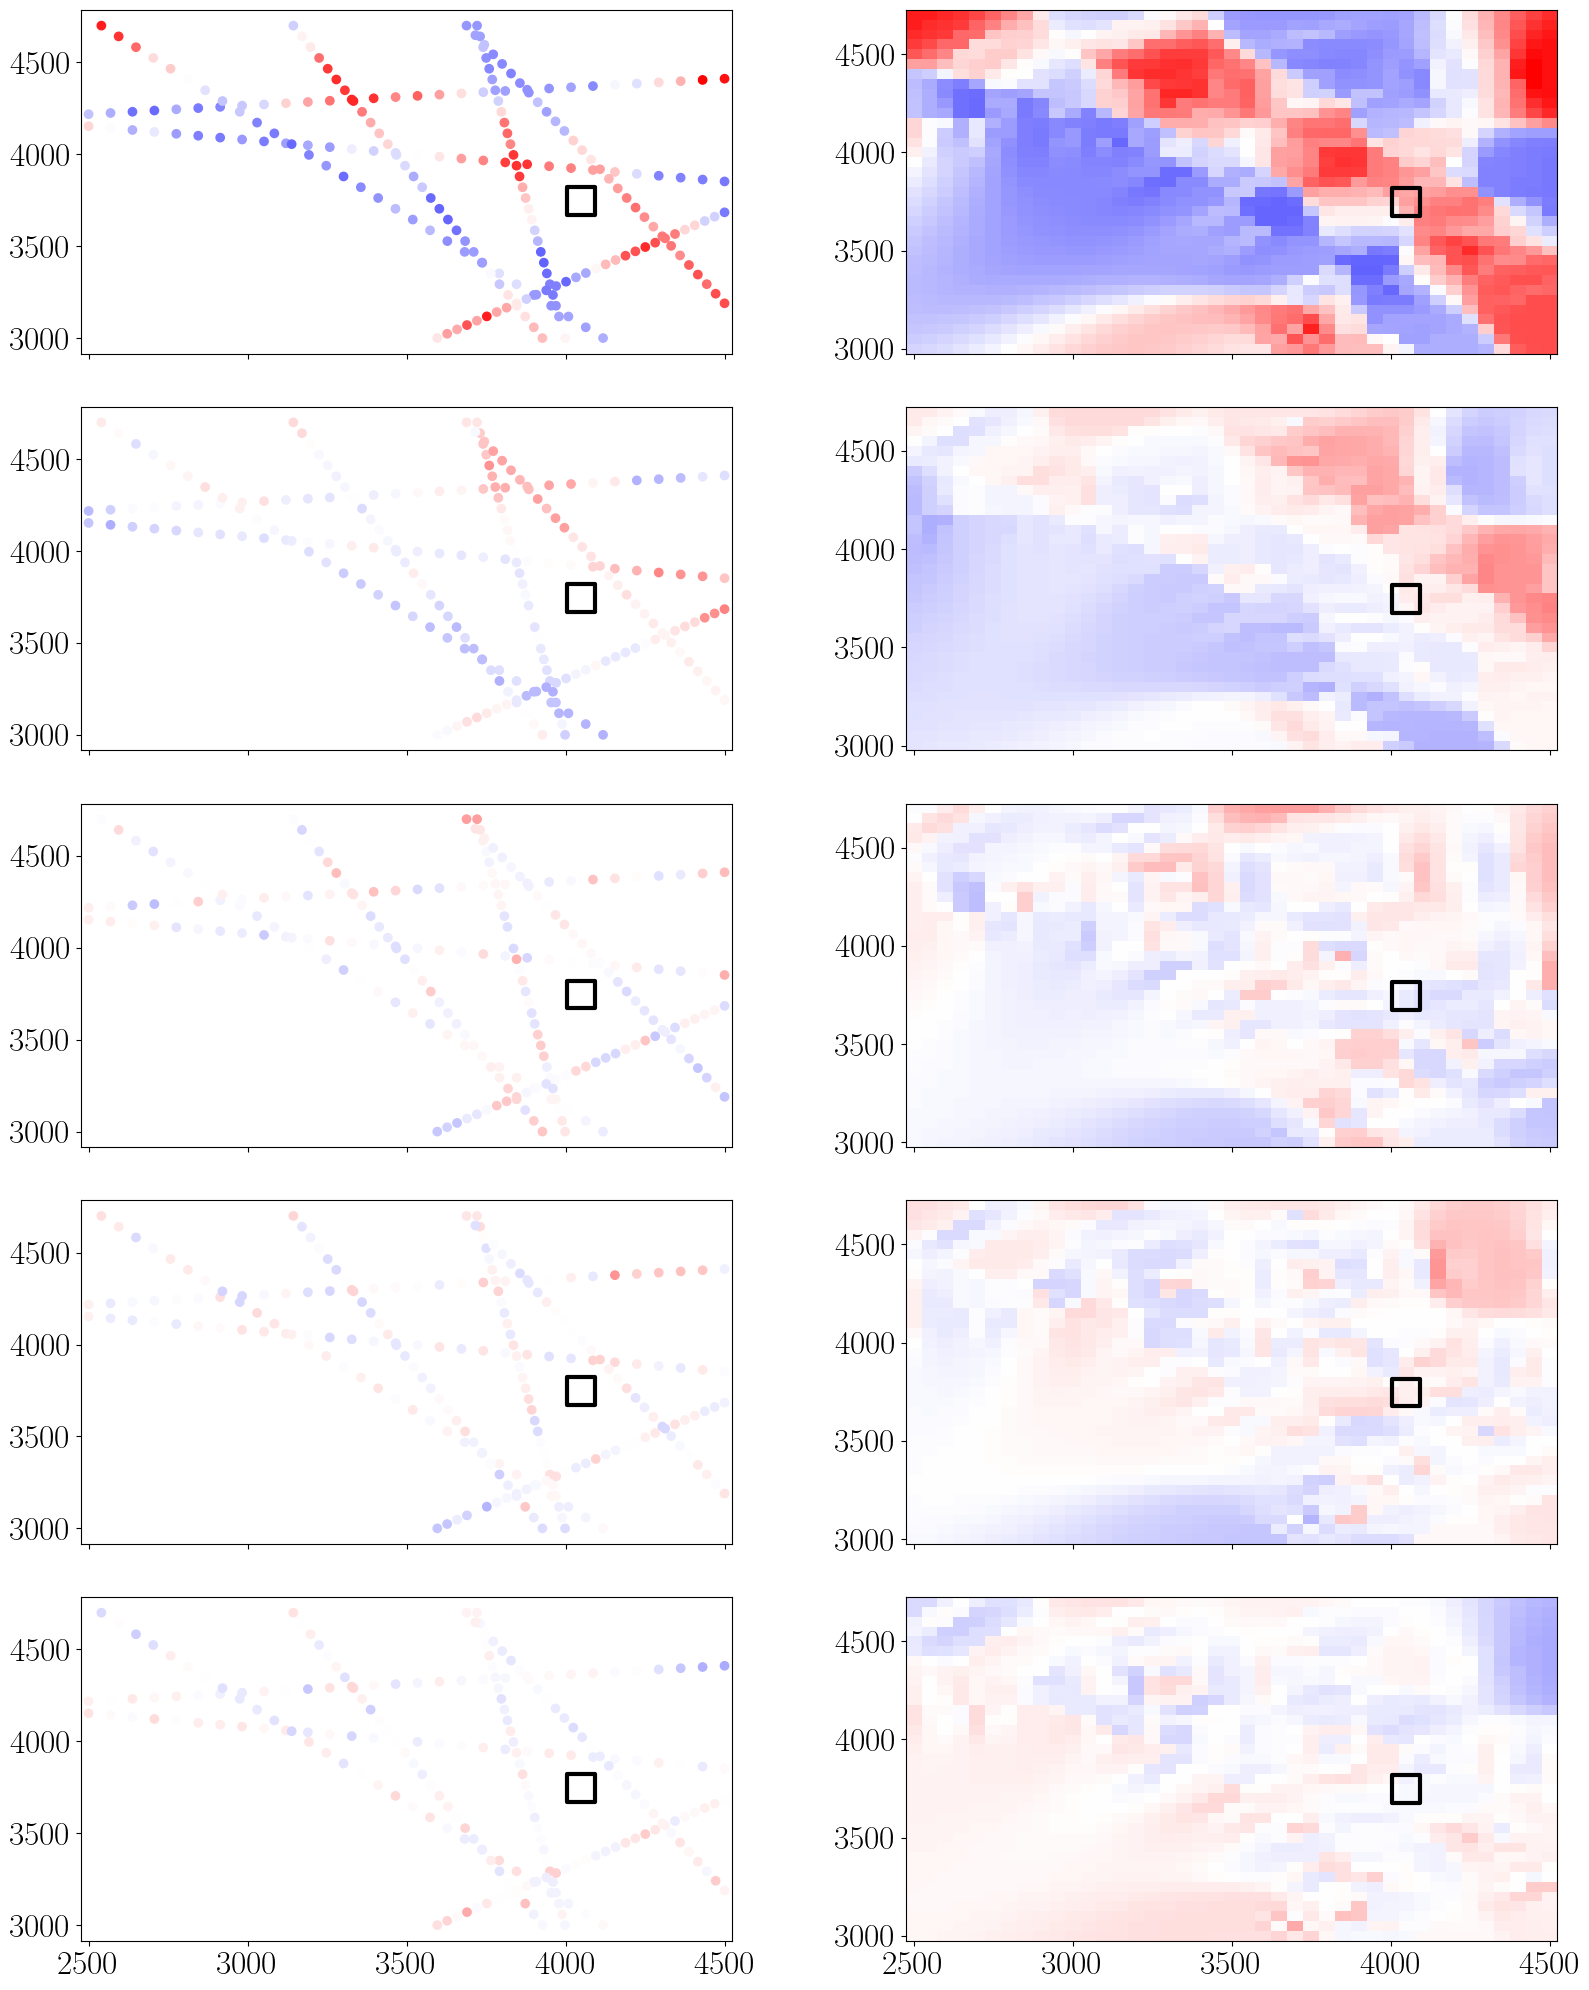

In [676]:
if low_dim <= 5:
    comp_to_plot = np.arange(low_dim)
else:
    comp_to_plot = np.linspace(0, low_dim, num=5, endpoint=False).astype(int)

ncomp = comp_to_plot.size 

fig, axs = plt.subplots(ncomp, 2, figsize=(16, 4*ncomp), sharex=True)
for i, icomp in enumerate(comp_to_plot):

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_gamma[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )

    psi_i_interp = coords_low_dim_grid[:, :, icomp]
    axs[i, 1].pcolormesh(
        x,
        y,
        psi_i_interp,
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

## Localisation avec la librairie interpolée 

In [677]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
coords_low_dim_X0 = coords_low_dim_grid[idx_y0, idx_x0, :]

In [678]:
d_L2_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim_grid - coords_low_dim_X0) ** 2,
        axis=-1,
    )
)
d_L2_low_dim /= np.max(d_L2_low_dim)

ind_min_L2_low_dim = np.argmin(d_L2_low_dim)
xmin_L2_low_dim, ymin_L2_low_dim = (
    xx.flatten()[ind_min_L2_low_dim],
    yy.flatten()[ind_min_L2_low_dim],
)

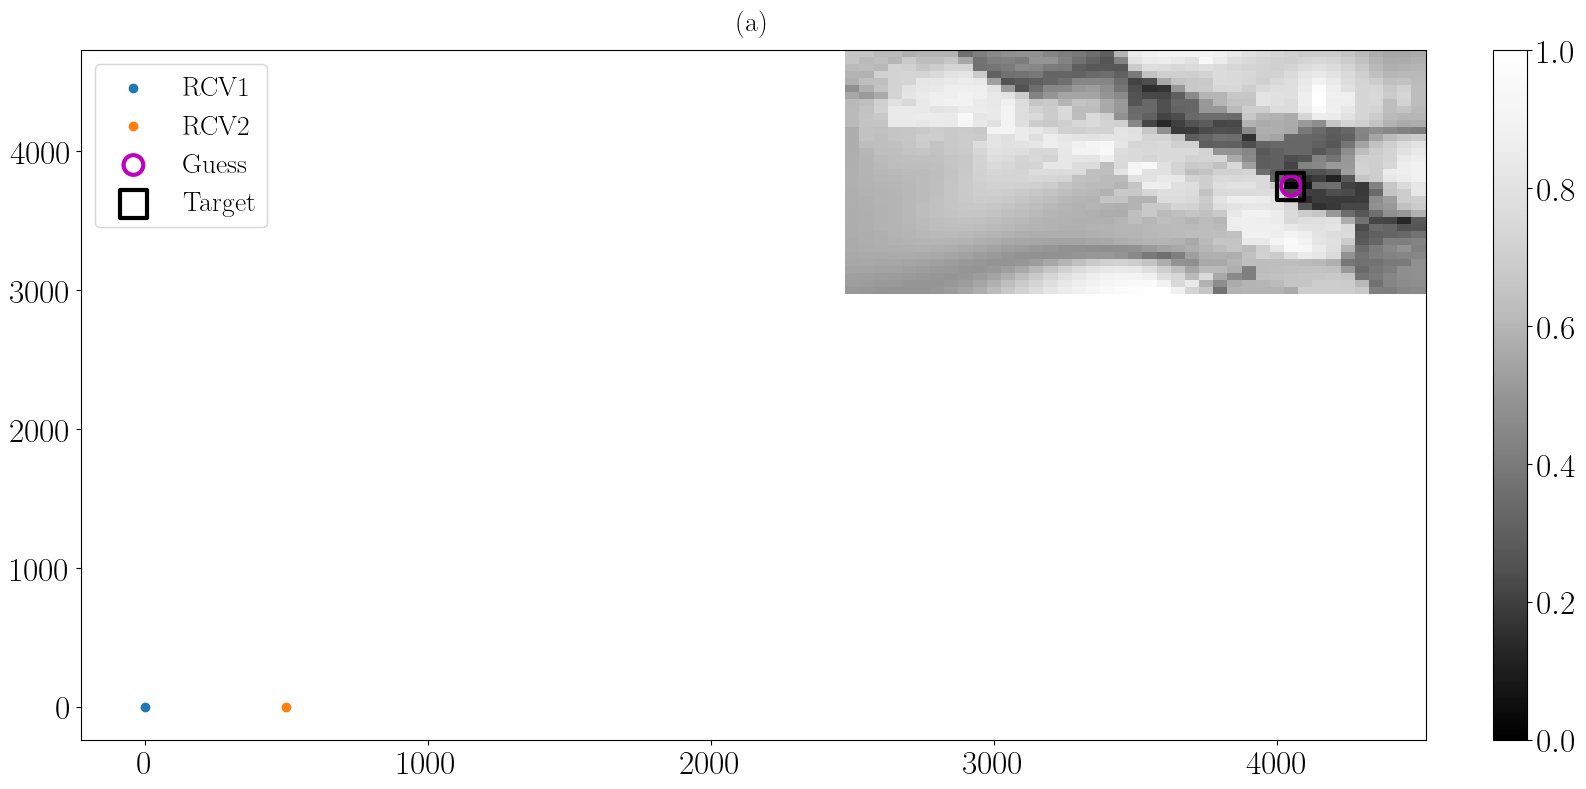

In [679]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, d_L2_low_dim, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_L2_low_dim,
    ymin_L2_low_dim,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2*r0,
#         height=2*r0,
#         angle=0,
#         theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
#         theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--"
#     )

#     ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

## Comparaison avec une interpolation directe sur le vecteur de RTF 

In [680]:
gamma_21_rr_sparse.shape, freq.size, xx_flat.shape[0]

((261, 210), 261, 1435)

In [681]:
# Interpolate each coords in low dim
power = 10

gamma_21_rr_sparse_grid = np.empty((xx_flat.shape[0], gamma_21_rr_sparse.shape[0]))
for ifreq in range(freq.size):
    gamma_freq_i = gamma_21_rr_sparse[ifreq, :]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(gamma_freq_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    gamma_freq_i_interp = numerator / weights

    gamma_21_rr_sparse_grid[:, ifreq] = gamma_freq_i_interp

# Reshape
gamma_21_rr_sparse_grid = np.reshape(
    gamma_21_rr_sparse_grid, xx.shape + (gamma_21_rr_sparse_grid.shape[1],)
)

In [682]:
gamma_21_rr_sparse.shape

(261, 210)

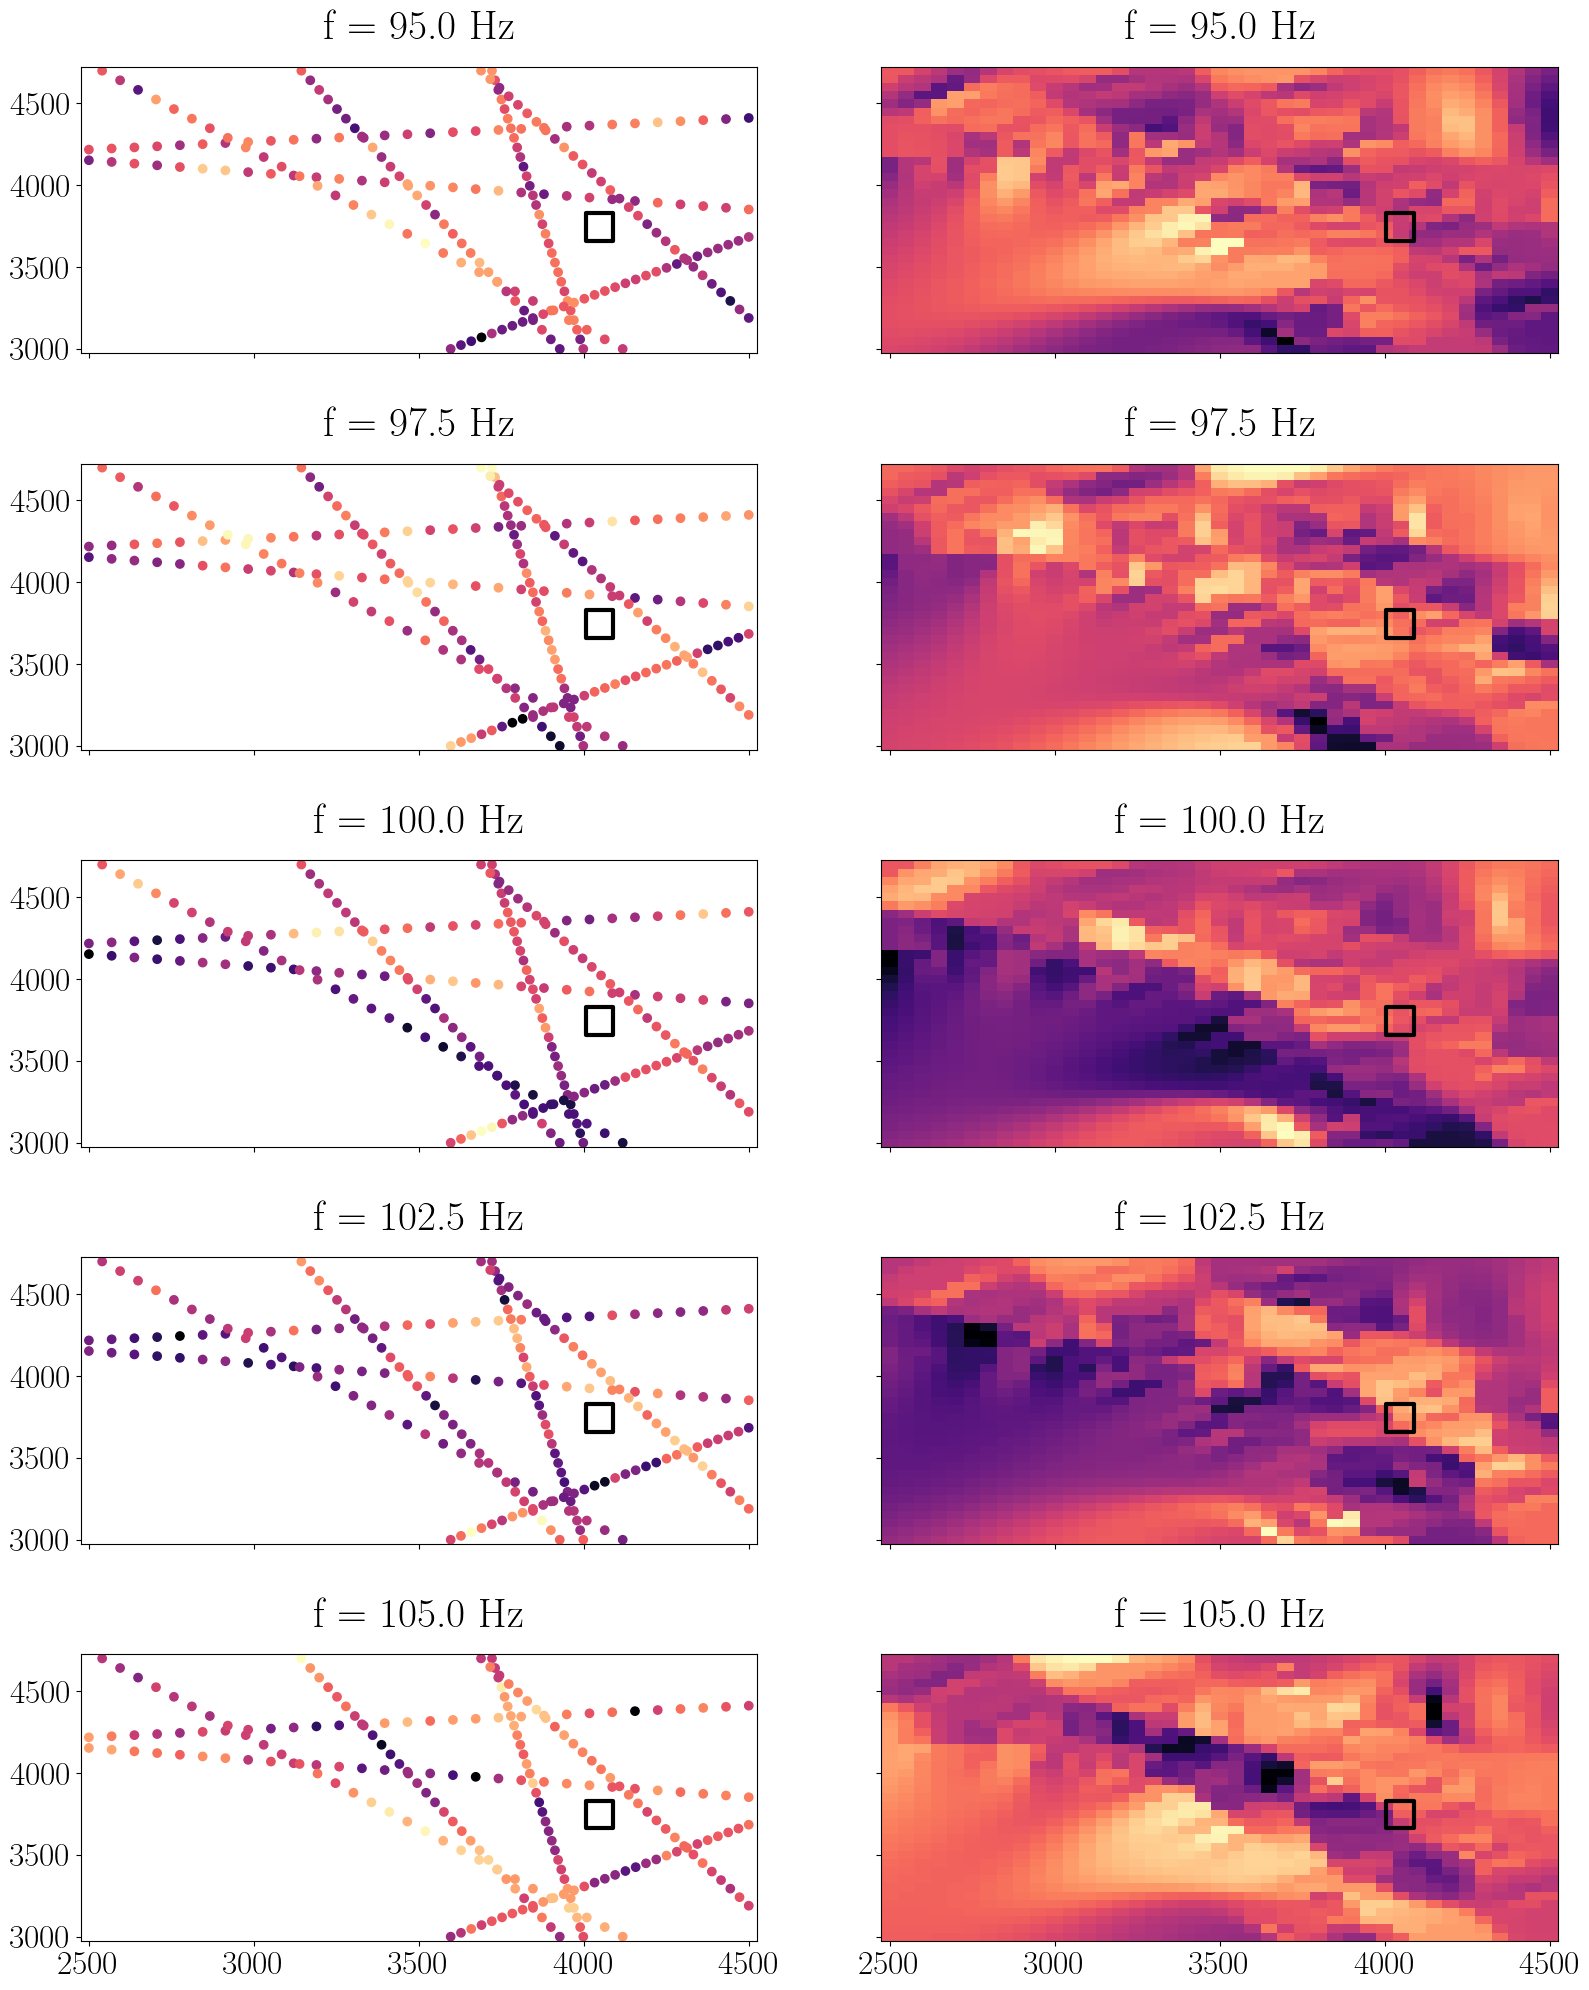

In [683]:

# if n_components <= 5:
#     comp_to_plot = np.arange(n_components)
# else:
#     comp_to_plot = np.linspace(0, n_components, num=5, endpoint=False).astype(int)

# ncomp = comp_to_plot.size 

# fig, axs = plt.subplots(ncomp, 3, figsize=(16, 4*ncomp), sharex=True)
# for i, icomp in enumerate(comp_to_plot):

# axs = axs.flatten()
freq_plot = [95, 97.5, 100, 102.5, 105]
fig, axs = plt.subplots(len(freq_plot), 2, figsize=(16, 4 * len(freq_plot)), sharex=True, sharey=True)

for i in range(len(freq_plot)):
    idx_f = np.argmin(np.abs(freq - freq_plot[i]))

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=gamma_21_rr_sparse[idx_f, :],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    # psi_i_interp = coords_low_dim_grid[:, :, idx_f]
    axs[i, 1].pcolormesh(
        x,
        y,
        gamma_21_rr_sparse_grid[:, :, idx_f],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    axs[i, 0].set_title(f"f = {freq[idx_f]} Hz")
    axs[i, 1].set_title(f"f = {freq[idx_f]} Hz")
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

In [684]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
gamma_21_rr_sparse_grid_r0 = gamma_21_rr_sparse_grid[idx_y0, idx_x0, :]

In [685]:
gamma_a = gamma_21_rr_sparse_grid_r0[:, np.newaxis]
gamma_b = gamma_21_rr_sparse_grid.reshape(
    gamma_21_rr_sparse_grid.shape[0] * gamma_21_rr_sparse_grid.shape[1],
    gamma_21_rr_sparse_grid.shape[2],
).T
print(gamma_a.shape, gamma_b.shape)
dist_theta_gamma_sparse_grid = calc_gamma_dist(gamma_a=gamma_a, gamma_b=gamma_b, dist_type="theta")
dist_theta_gamma_sparse_grid /= np.max(dist_theta_gamma_sparse_grid)

ind_min_gamma_sparse_grid = np.argmin(dist_theta_gamma_sparse_grid)
xmin_gamma_sparse_grid, ymin_gamma_sparse_grid = (
    xx.flatten()[ind_min_gamma_sparse_grid],
    yy.flatten()[ind_min_gamma_sparse_grid],
)

(261, 1) (261, 1435)


In [686]:
dist_theta_gamma_sparse_grid.shape

(1435,)

In [687]:
dist_theta_gamma_sparse_grid = dist_theta_gamma_sparse_grid.reshape(
    gamma_21_rr_sparse_grid.shape[0:2]
)

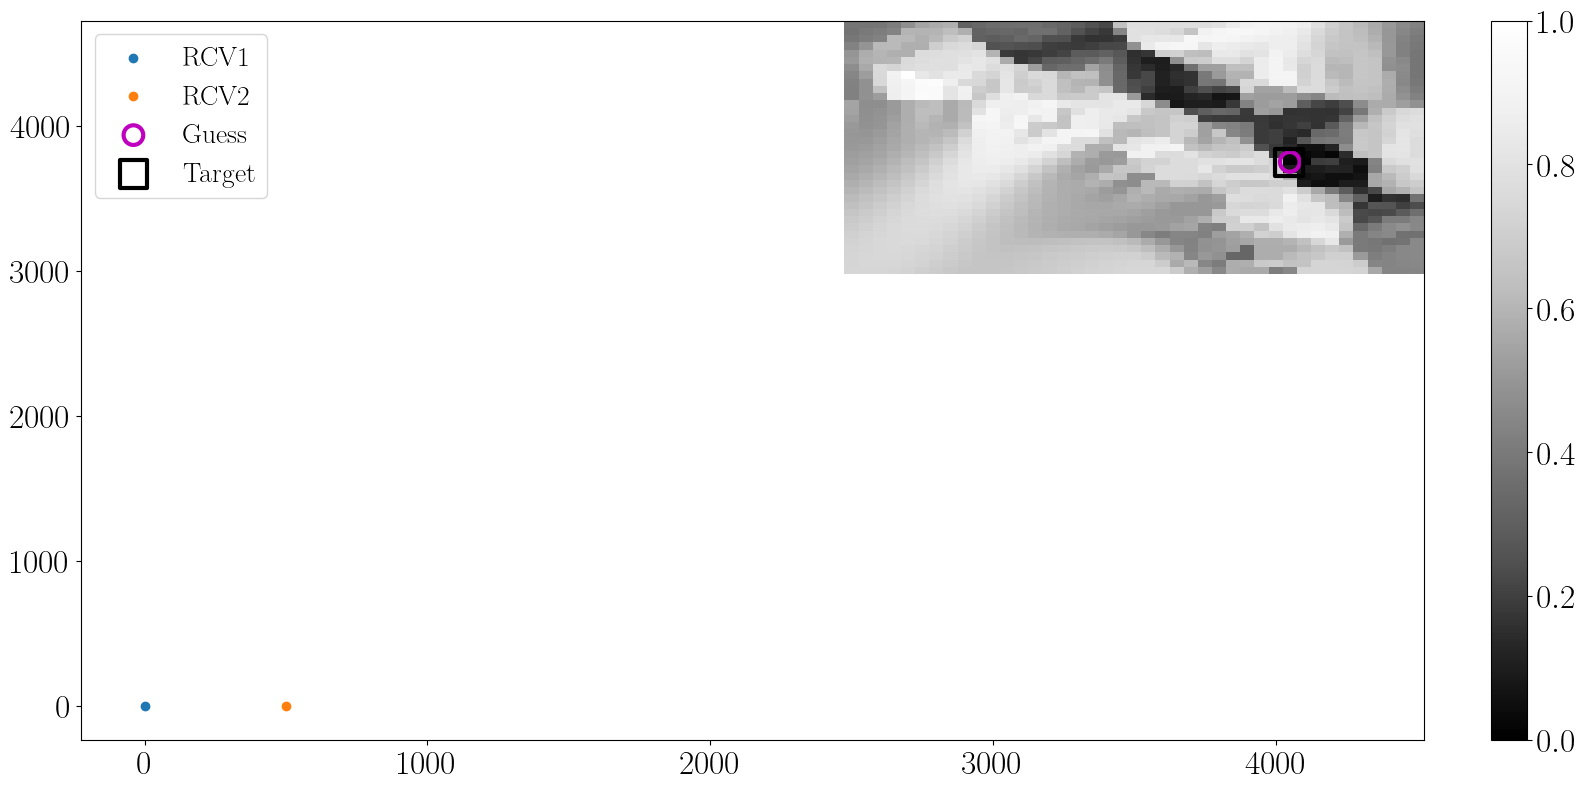

In [688]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, dist_theta_gamma_sparse_grid, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_gamma_sparse_grid,
    ymin_gamma_sparse_grid,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2*r0,
#         height=2*r0,
#         angle=0,
#         theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
#         theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--"
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

**Bilan**

On peut effectivement reconstruire la surface d'ambiguïté en interpolant les composantes obtenues après réduction de dimension à l'aide de la méthode ISOMAP. Cependant, les performances sont comparables à une approche basée sur l'interpolation spatiale de chacune des composantes fréquentielles et il n'est pas clair évident à ce stade que l'approche par apprentissage de variété présente un avantage notable.

Afin d'éclaircir ce point, on peut regarder deux choses :

* Effet du bruit : l'interpolation spatiale avec des composantes fréquentielles bruitées (bruit d'estimation des RTFs) doit probablement dégradée les performances. On sait également que le bruit sur les RTF peut induire des points aberrant dans le jeu de données utilisé pour l'apprentissage de variété. Or les méthodes d'apprentissage de variété sont connue pour être particulièrement sensible à la présence d'outliers dans les données et le traitement de ces cas est un sujet de recherche ouvert.  
* Rang des matrices : le papier Sitian Wang, Ting Zhang, Jianlong Li, Wen Xu, Peter Gerstoft; Physics-guided Bayesian matrix completion of replica libraries for underwater source localization. J. Acoust. Soc. Am. 1 October 2026; 160 (4): 2756–2768 récemment publié dans JASA étudie une méthode de completion (équivalent interpolation). Dans le papier les auteurs utilise une normalisation par la fonction de Hankel pour limiter le rang effectif de la librarie de répliques : "The impact of the ET on the effective rank of the replica library is further investigated through singular value analysis". En effet, d'après eux :  "reducing the effective rank of the replica library can reduce the observation ratio required for successful completion under sparse sampling conditions."


# Rang des matrices 

Comparaison basée sur la démarche utilisée dans la section III de l'article :

Sitian Wang, Ting Zhang, Jianlong Li, Wen Xu, Peter Gerstoft; Physics-guided Bayesian matrix completion of replica libraries for underwater source localization. J. Acoust. Soc. Am. 1 October 2026; 160 (4): 2756–2768



In [699]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr_.T  # (n_sample, n_features) = (n_pos, nfreq)

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# ### RTF (Pi) ###
# Learn manifold and project data in target dimension
pi_21_ = pi_21_rr_.T  # (n_pos, nfreq)

# Calc theta with pi
inner_prod = np.nansum(
    pi_21_[np.newaxis, :, :] * np.conj(pi_21_)[:, np.newaxis, :], axis=-1
)
norm_a = np.sqrt(
    np.nansum(pi_21_[np.newaxis, :, :] * np.conj(pi_21_)[np.newaxis, :, :], axis=-1)
)
norm_b = np.sqrt(
    np.nansum(pi_21_[:, np.newaxis, :] * np.conj(pi_21_)[:, np.newaxis, :], axis=-1)
)
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

### DCF ###
c12_ = c21_rr_.T
# Subsample to reduce memory
# c12_ = c12_[::2, :]
dist_mat = np.abs(
    np.nansum(
        c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
        axis=-1,
    )
)
dist_mat = dist_mat / np.max(dist_mat)
dist_mat_dcf = 1 - dist_mat

In [720]:
n_components = 20
n_neighbors = 10
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# # ### RTF (Pi) ###
# # Define isomap object
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
# )
# # Project
# coords_isompa_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
# coords_isompa_pi = coords_isompa_pi / np.max(np.abs(coords_isompa_pi))

# # ### DCF ###
# # Define isomap object
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
# )
# # Project
# coords_isompa_dcf = isomap_obj.fit_transform(dist_mat_dcf)
# coords_isompa_dcf = coords_isompa_dcf / np.max(np.abs(coords_isompa_dcf))

In [721]:
# Reshape coords to 2D grid shape (y, x, n_components)
shape = (y.size, x.size, n_components)
coords_isomap_gamma = coords_isomap_gamma.reshape(shape)

In [722]:
cumulative_energy_ratio_arr = []
for f in freq:
    gamma_f = gamma_21_rr.sel(freq=f)
    U, S, Vh = np.linalg.svd(gamma_f.values)

    cumulative_energy_ratio = np.cumsum(S**2) / np.sum(S**2)
    cumulative_energy_ratio_arr.append(cumulative_energy_ratio)

cumulative_energy_ratio_arr = np.array(cumulative_energy_ratio_arr)

In [724]:
cumulative_energy_ratio_isomap_arr = []
for icomp in range(coords_isomap_gamma.shape[-1]):
    gamma_comp = coords_isomap_gamma[..., icomp]
    U, S, Vh = np.linalg.svd(gamma_comp)

    cumulative_energy_ratio = np.cumsum(S**2) / np.sum(S**2)
    cumulative_energy_ratio_isomap_arr.append(cumulative_energy_ratio)

cumulative_energy_ratio_isomap_arr = np.array(cumulative_energy_ratio_isomap_arr)

Text(0.02, 0.5, 'Number of components')

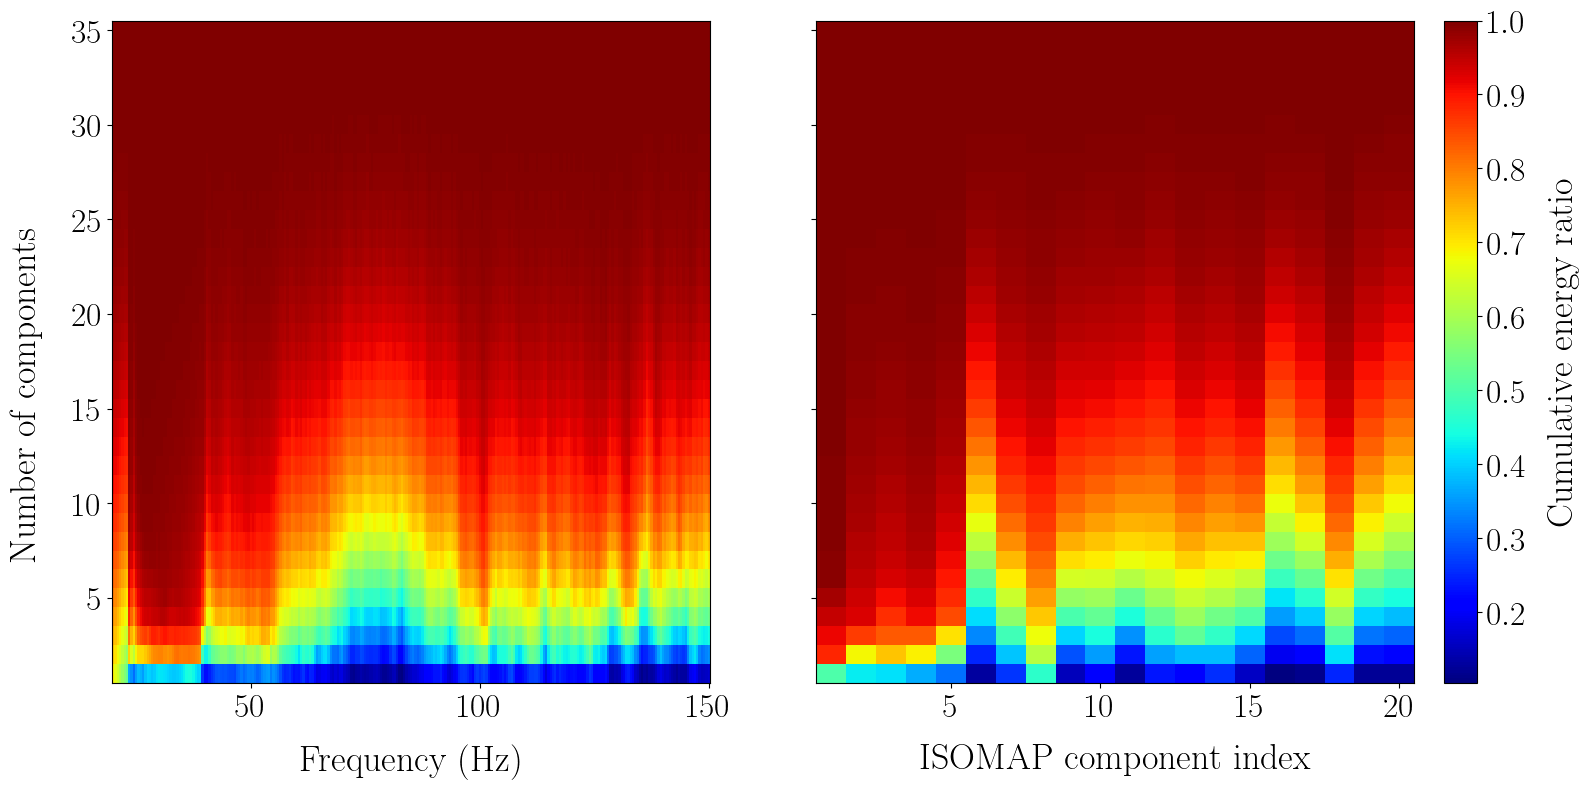

In [728]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
im = axs[0].pcolormesh(
    freq,
    np.arange(1, cumulative_energy_ratio_arr.shape[1] + 1),
    cumulative_energy_ratio_arr.T,
    cmap="jet",
    shading="auto",
)
axs[0].set_xlabel("Frequency (Hz)")

im = axs[1].pcolormesh(
    np.arange(1, cumulative_energy_ratio_isomap_arr.shape[0] + 1),
    np.arange(1, cumulative_energy_ratio_isomap_arr.shape[1] + 1),
    cumulative_energy_ratio_isomap_arr.T,
    cmap="jet",
    shading="auto",
)
plt.colorbar(im, label="Cumulative energy ratio")
axs[1].set_xlabel("ISOMAP component index")
fig.supylabel("Number of components")

**Bilan**

Les premières composantes sont de rang effectif faible ce qui n'est pas le cas de l'ensemble des bins fréquentiels. Si l'on ne conserve que les premières composantes alors on peut appliquer l'approche proposée dans le papier cité plus haut pour stratégie d'interpolation. 


# Effet du bruit 

On bruite les RTFs et on applique la même procédure que précédemment.

## Ajout de bruit 

In [786]:
snr_dB = -5
sigma_g = np.std(gamma_21_rr.values)
sigma_noise = sigma_g * 10**(-snr_dB / 20)

gamma_21_rr_noisy = gamma_21_rr + sigma_noise * np.random.randn(*gamma_21_rr.values.shape)

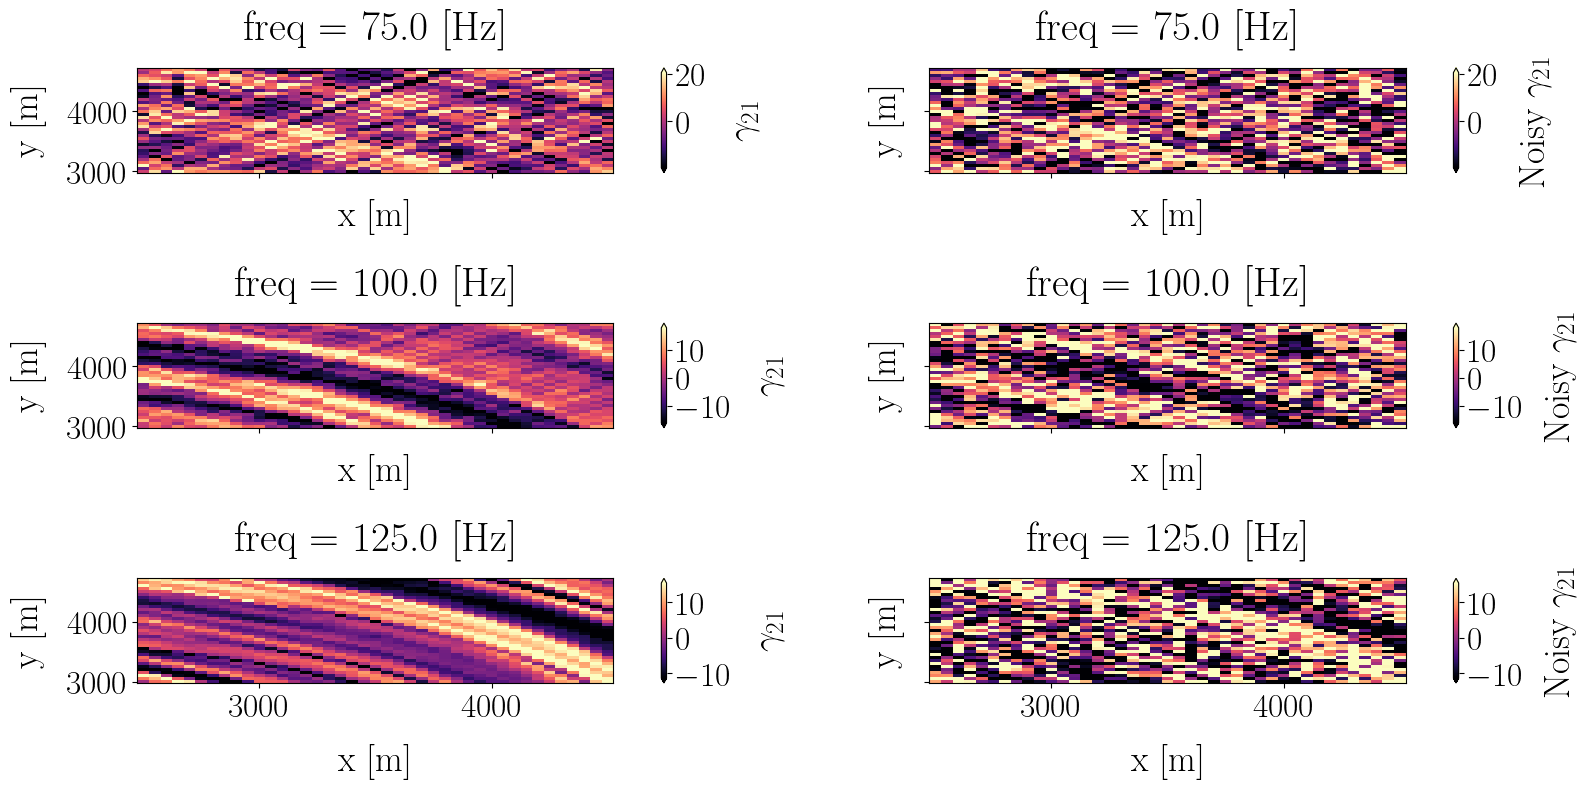

In [787]:
fig, axs = plt.subplots(3, 2, figsize=(16, 8), sharex=True, sharey=True)
freq_plot = [75, 100, 125]
for ifreq, f in enumerate(freq_plot):
    vmin = np.percentile(gamma_21_rr.sel(freq=f).values, 5)
    vmax = np.percentile(gamma_21_rr.sel(freq=f).values, 95)
    gamma_21_rr.sel(freq=f, method="nearest").plot(
        x="x",
        cmap="magma",
        vmin=vmin,
        vmax=vmax,
        ax=axs[ifreq, 0],
        cbar_kwargs={"label": r"$\gamma_{21}$"},
    )
    gamma_21_rr_noisy.sel(freq=f, method="nearest").plot(
        x="x",
        cmap="magma",
        vmin=vmin,
        vmax=vmax,
        ax=axs[ifreq, 1],
        cbar_kwargs={"label": r"Noisy $\gamma_{21}$"},
    )

## Génération des tracks 

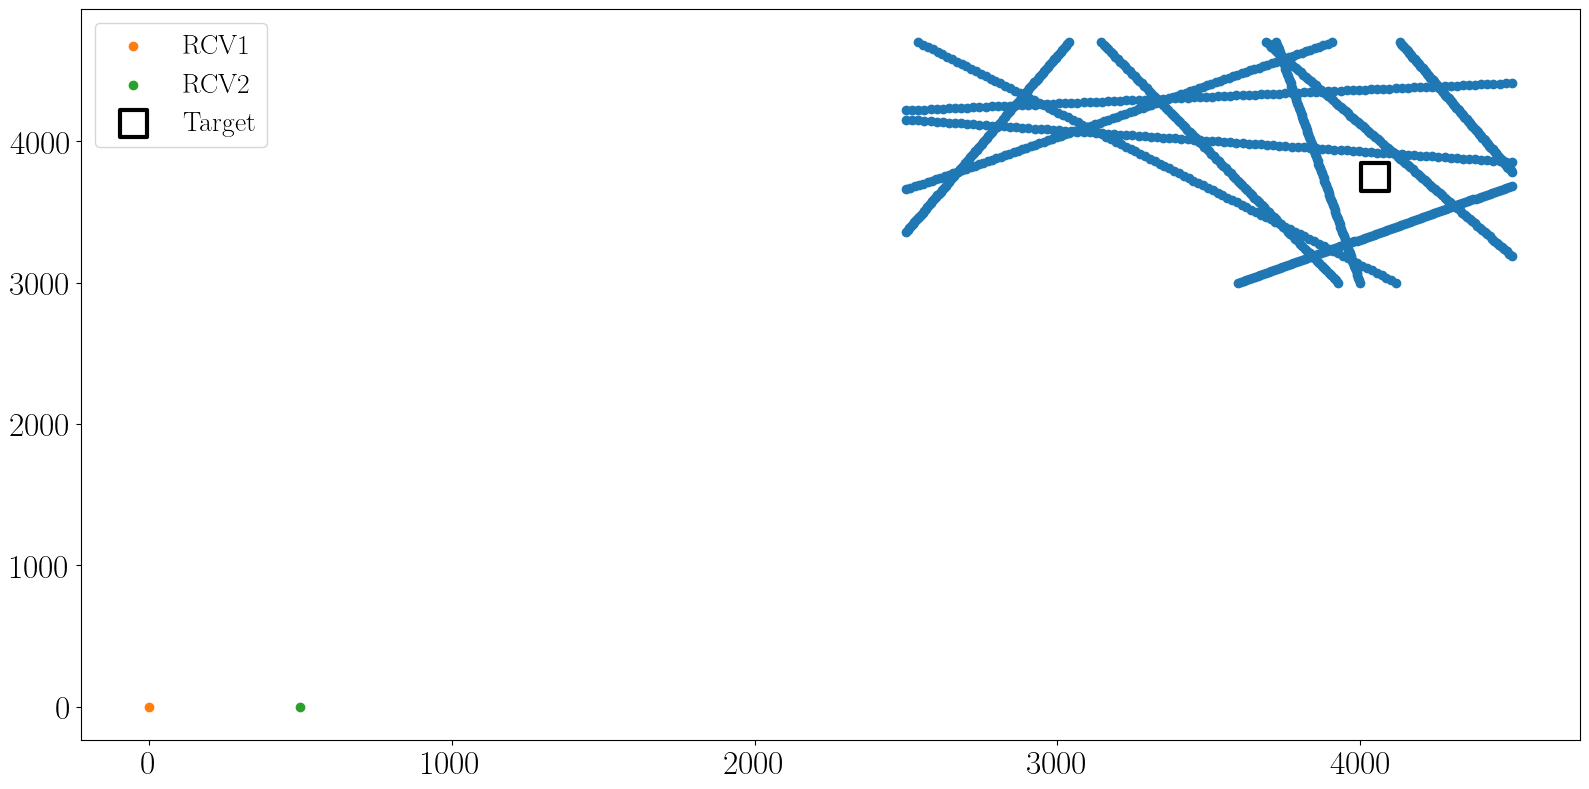

In [805]:
# ntracks = 5
random_seed = 4
x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=10, npt=100, random_seed=random_seed)      # OK pour 15
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=10, npt=100, random_seed=random_seed)        # Ok pour 10
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=100, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5
# x_tracks, y_tracks = generate_ship_tracks(x, y, ntracks=5, npt=200, random_seed=random_seed)        # Loc ok mais surface avec plusieurs lobes pour 5
x_lib_sparse = np.concat(x_tracks)
y_lib_sparse = np.concat(y_tracks)
ntracks = len(x_tracks)

plt.scatter(
    x_lib_sparse,
    y_lib_sparse,
)
plt.scatter(
    x_rcv1,
    y_rcv1,
    label="RCV1",
)
plt.scatter(
    x_rcv2,
    y_rcv2,
    label="RCV2",
)
plt.scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
plt.legend()

## Extraction des RTF le long des trajectoires 

In [806]:
_, gamma_21_rr_sparse, _ = get_features_along_tracks(
    x_tracks, y_tracks, pi_21_rr, gamma_21_rr_noisy, c21_rr
)

## Apprentissage de variété 

In [807]:
### RTF (Gamma) ###
gamma_ = gamma_21_rr_sparse.T  # (n_sample, n_features) = (n_pos, nfreq)

# Subsample
# gamma_ = gamma_[::10, :]

# Remove nan
idx_f_no_nan = ~np.isnan(gamma_[0, :])
gamma_ = gamma_[:, idx_f_no_nan]

gamma_a = gamma_[np.newaxis, :, :]
gamma_b = gamma_[:, np.newaxis, :]
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_mat_rtf_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

# # ### RTF (Pi) ###
# # Learn manifold and project data in target dimension
# pi_21_rr_ = pi_21_rr_sparse.T  # (n_pos, nfreq)

# # Calc theta with pi
# inner_prod = np.nansum(
#     pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
# )
# norm_a = np.sqrt(
#     np.nansum(
#         pi_21_rr_[np.newaxis, :, :] * np.conj(pi_21_rr_)[np.newaxis, :, :], axis=-1
#     )
# )
# norm_b = np.sqrt(
#     np.nansum(
#         pi_21_rr_[:, np.newaxis, :] * np.conj(pi_21_rr_)[:, np.newaxis, :], axis=-1
#     )
# )
# # Clip to [0, 1] for stability
# cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
# dist_mat_rtf_pi = 1 - cos_angle  #  to [0, 1]

# ### DCF ###
# c12_ = c21_rr_sparse.T
# # Subsample to reduce memory
# # c12_ = c12_[::2, :]
# dist_mat = np.abs(
#     np.nansum(
#         c12_[np.newaxis, :, :] * np.conj(c12_[:, np.newaxis, :]),
#         axis=-1,
#     )
# )
# dist_mat = dist_mat / np.max(dist_mat)
# dist_mat_dcf = 1 - dist_mat

In [808]:
n_components = 25
n_neighbors = 25
### RTF (Gamma) ###
# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
)
# Project
coords_isomap_gamma = isomap_obj.fit_transform(dist_mat_rtf_gamma)
coords_isomap_gamma = coords_isomap_gamma / np.max(np.abs(coords_isomap_gamma))

# # ### RTF (Pi) ###
# # Define isomap object
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
# )
# # Project
# coords_isomap_pi = isomap_obj.fit_transform(dist_mat_rtf_pi)
# coords_isomap_pi = coords_isomap_pi / np.max(np.abs(coords_isomap_pi))

# # ### DCF ###
# # Define isomap object
# isomap_obj = manifold.Isomap(
#     n_neighbors=n_neighbors, n_components=n_components, metric="precomputed"
# )
# # Project
# coords_isomap_dcf = isomap_obj.fit_transform(dist_mat_dcf)
# coords_isomap_dcf = coords_isomap_dcf / np.max(np.abs(coords_isomap_dcf))

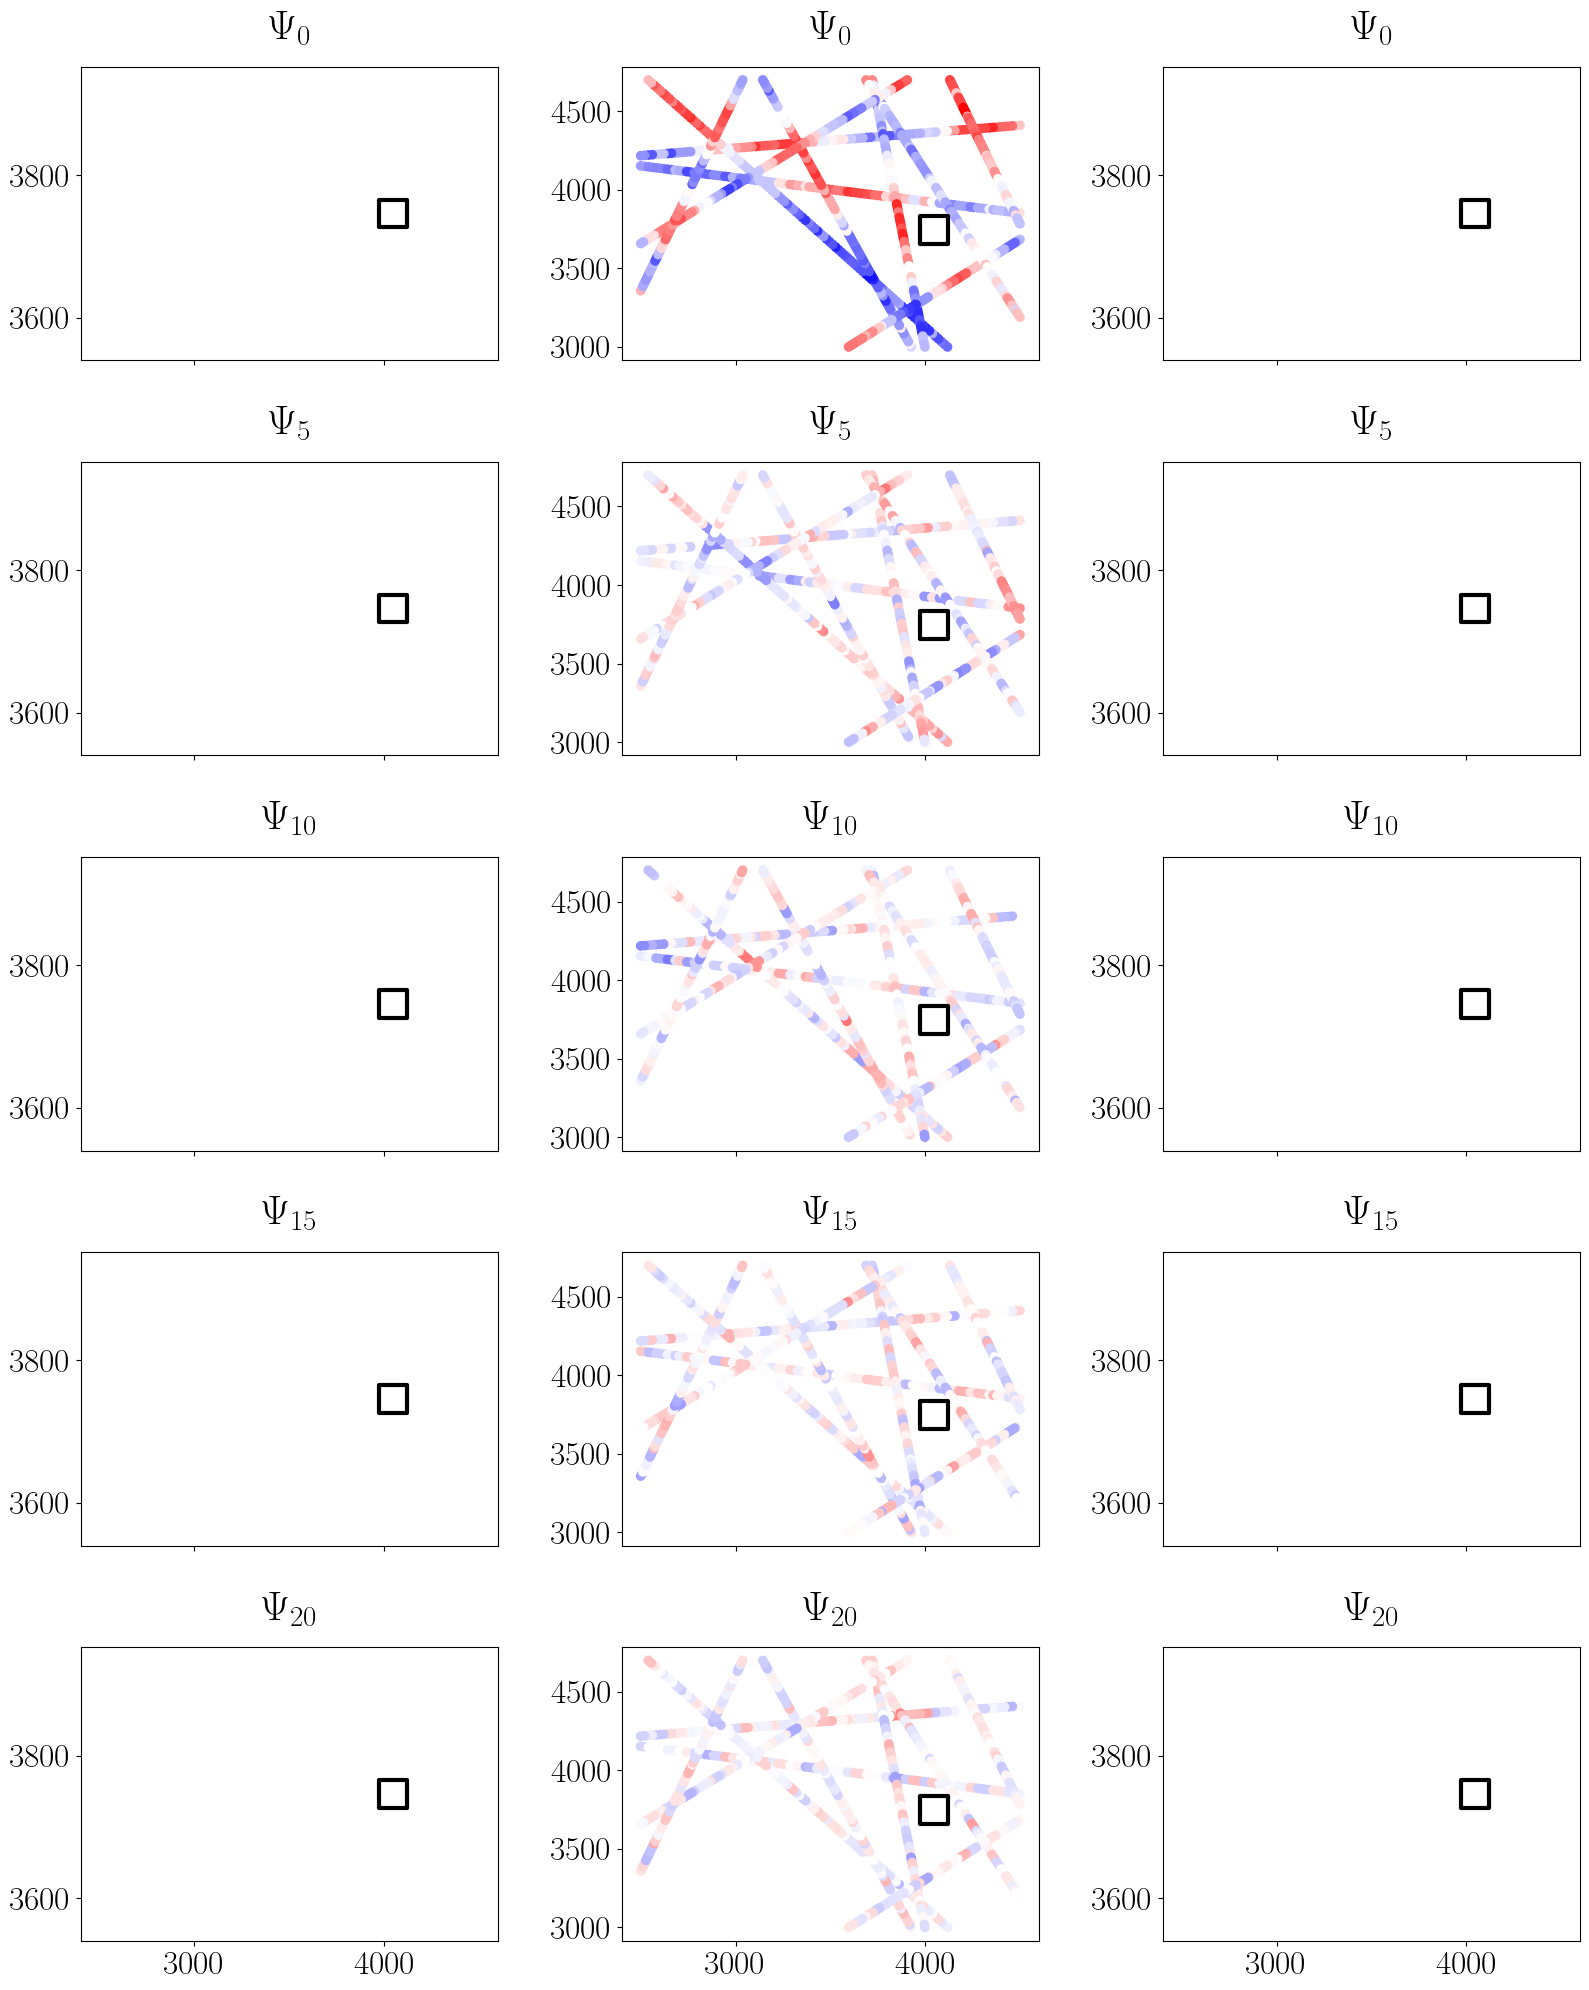

In [810]:
# axs = axs.flatten()
if n_components <= 5:
    comp_to_plot = np.arange(n_components)
else:
    comp_to_plot = np.linspace(0, n_components, num=5, endpoint=False).astype(int)

ncomp = comp_to_plot.size 

fig, axs = plt.subplots(ncomp, 3, figsize=(16, 4*ncomp), sharex=True)
for i, icomp in enumerate(comp_to_plot):
    # axs[i, 0].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isomap_pi[..., icomp],
    #     cmap="bwr",
    #     vmin=-1,
    #     vmax=1,
    # )
    axs[i, 1].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_gamma[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isomap_dcf[..., icomp],
    #     cmap="bwr",
    #     vmin=-1,
    #     vmax=1,
    # )

    axs[i, 0].set_title(rf"$\Psi_{{{icomp}}}$")
    axs[i, 1].set_title(rf"$\Psi_{{{icomp}}}$")
    axs[i, 2].set_title(rf"$\Psi_{{{icomp}}}$")


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

## Interpolation des coordonnées en projection 

In [811]:
xx, yy = np.meshgrid(ds.x.values, ds.y.values)
xx_flat = xx.flatten()
yy_flat = yy.flatten()

dx_grid_lib = xx_flat[:, np.newaxis] - x_lib_sparse[np.newaxis, :]  # (n_xx, n_xlib)
dy_grid_lib = yy_flat[:, np.newaxis] - y_lib_sparse[np.newaxis, :]  # (n_yy, n_ylib)
r_grid_lib = np.sqrt(dx_grid_lib**2 + dy_grid_lib**2)
r_grid_lib.shape

# # check this is okay
# i, j = -1, -1
# print(
#     f"Distance from grid point of coords e={xx_flat[i]}, n={yy_flat[i]} : {r_grid_lib[i, :]}"
# )
# # Non vectorized calc for comparison
# x_test = xx_flat[i]
# y_test = yy_flat[i]
# r_test = np.sqrt((x_test - x_lib_sparse) ** 2 + (y_test - y_lib_sparse) ** 2)
# print(np.allclose(r_test, r_grid_lib[i, :]))

(1435, 1000)

In [812]:
# Interpolate each coords in low dim
i = 0
power = 2

low_dim = 10
coords_low_dim = coords_isomap_gamma[:, :low_dim]
coords_low_dim_grid = np.empty((xx_flat.shape[0], coords_low_dim.shape[1]))
for i in range(low_dim):
    psi_i = coords_low_dim[:, i]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(psi_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    psi_i_interp = numerator / weights

    coords_low_dim_grid[:, i] = psi_i_interp

# Reshape
coords_low_dim_grid = np.reshape(
    coords_low_dim_grid, xx.shape + (coords_low_dim_grid.shape[1],)
)

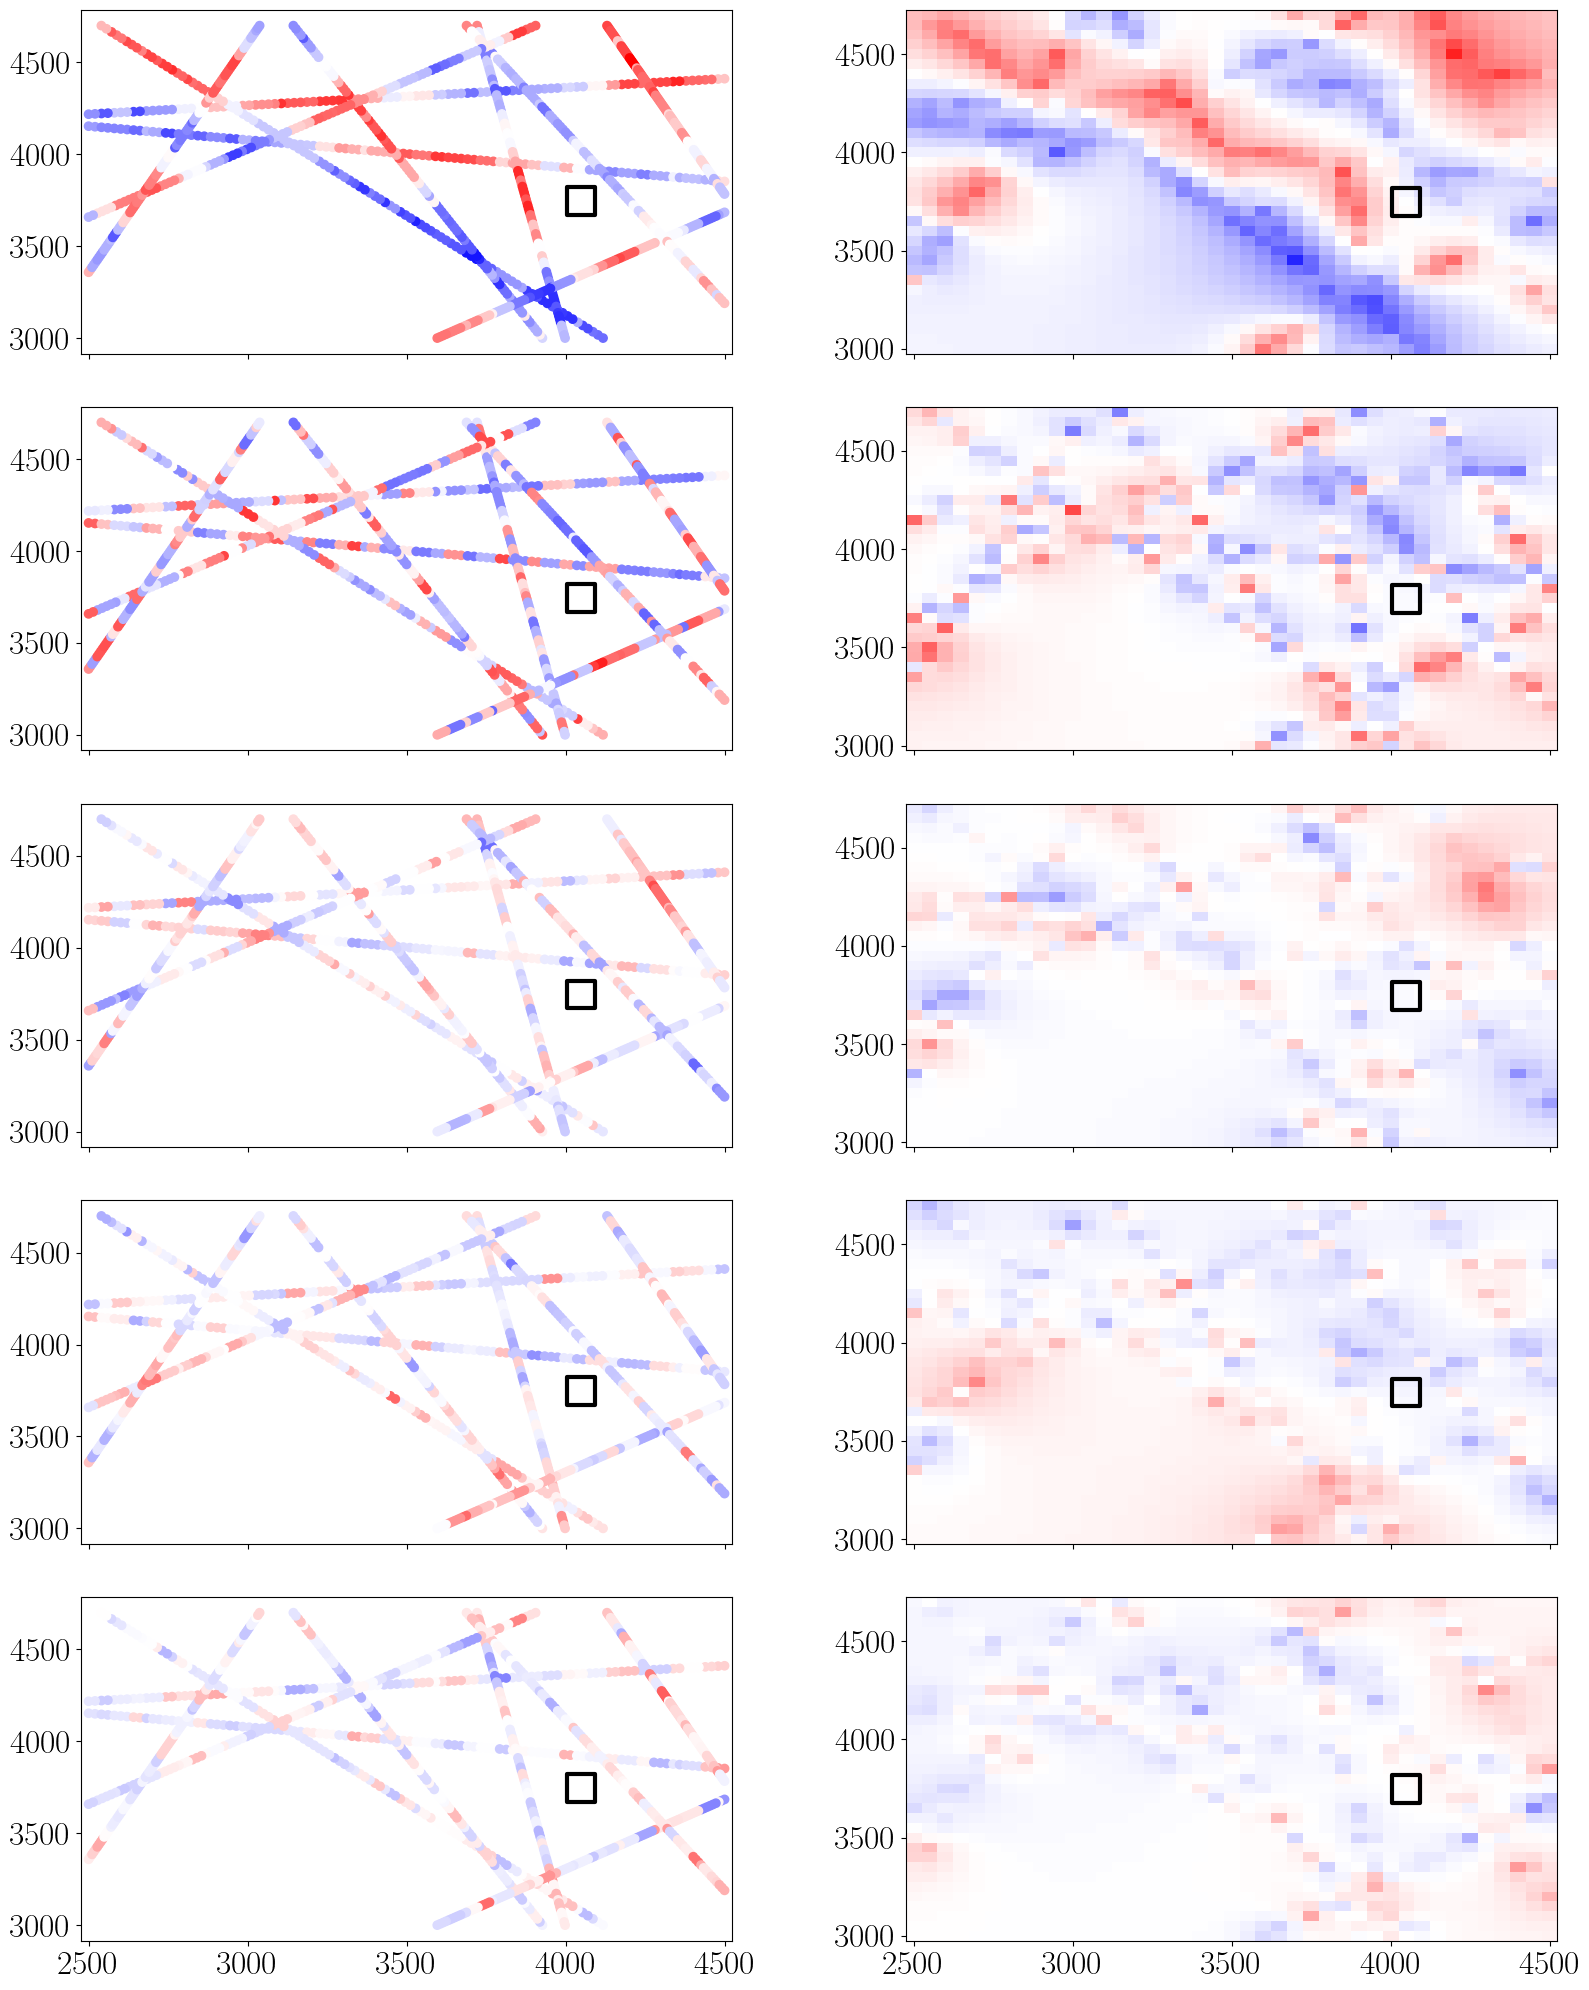

In [813]:
if low_dim <= 5:
    comp_to_plot = np.arange(low_dim)
else:
    comp_to_plot = np.linspace(0, low_dim, num=5, endpoint=False).astype(int)

ncomp = comp_to_plot.size 

fig, axs = plt.subplots(ncomp, 2, figsize=(16, 4*ncomp), sharex=True)
for i, icomp in enumerate(comp_to_plot):

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=coords_isomap_gamma[..., icomp],
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )

    psi_i_interp = coords_low_dim_grid[:, :, icomp]
    axs[i, 1].pcolormesh(
        x,
        y,
        psi_i_interp,
        cmap="bwr",
        vmin=-1,
        vmax=1,
    )
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

## Localisation avec la librairie interpolée 

In [814]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
coords_low_dim_X0 = coords_low_dim_grid[idx_y0, idx_x0, :]

In [815]:
d_L2_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim_grid - coords_low_dim_X0) ** 2,
        axis=-1,
    )
)
d_L2_low_dim /= np.max(d_L2_low_dim)

ind_min_L2_low_dim = np.argmin(d_L2_low_dim)
xmin_L2_low_dim, ymin_L2_low_dim = (
    xx.flatten()[ind_min_L2_low_dim],
    yy.flatten()[ind_min_L2_low_dim],
)

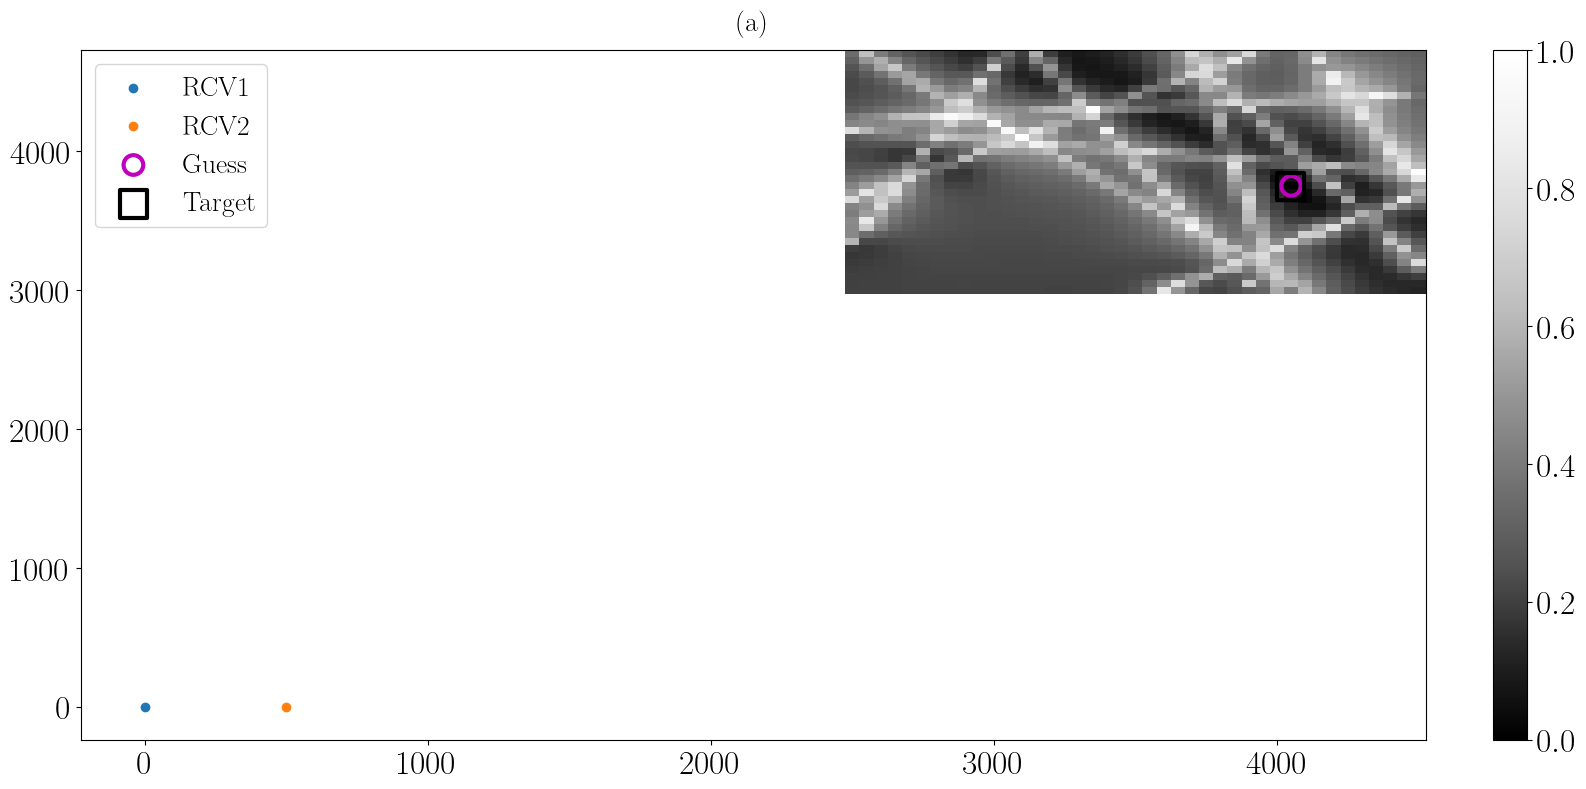

In [816]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, d_L2_low_dim, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_L2_low_dim,
    ymin_L2_low_dim,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2*r0,
#         height=2*r0,
#         angle=0,
#         theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
#         theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--"
#     )

#     ax.add_patch(arc0)


set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

## Comparaison avec une interpolation directe sur le vecteur de RTF 

In [817]:
# Interpolate each coords in low dim

gamma_21_rr_sparse_grid = np.empty((xx_flat.shape[0], gamma_21_rr_sparse.shape[0]))
for ifreq in range(freq.size):
    gamma_freq_i = gamma_21_rr_sparse[ifreq, :]
    # Calculate the weighted sum of known values based on distances
    numerator = np.sum(gamma_freq_i[np.newaxis, :] / (r_grid_lib**power), axis=1)

    # Calculate the sum of weights (inverse of distances)
    weights = np.sum(1 / (r_grid_lib**power), axis=1)

    # Calculate the interpolated value using Inverse Distance Weighting (IDW) formula
    gamma_freq_i_interp = numerator / weights

    gamma_21_rr_sparse_grid[:, ifreq] = gamma_freq_i_interp

# Reshape
gamma_21_rr_sparse_grid = np.reshape(
    gamma_21_rr_sparse_grid, xx.shape + (gamma_21_rr_sparse_grid.shape[1],)
)

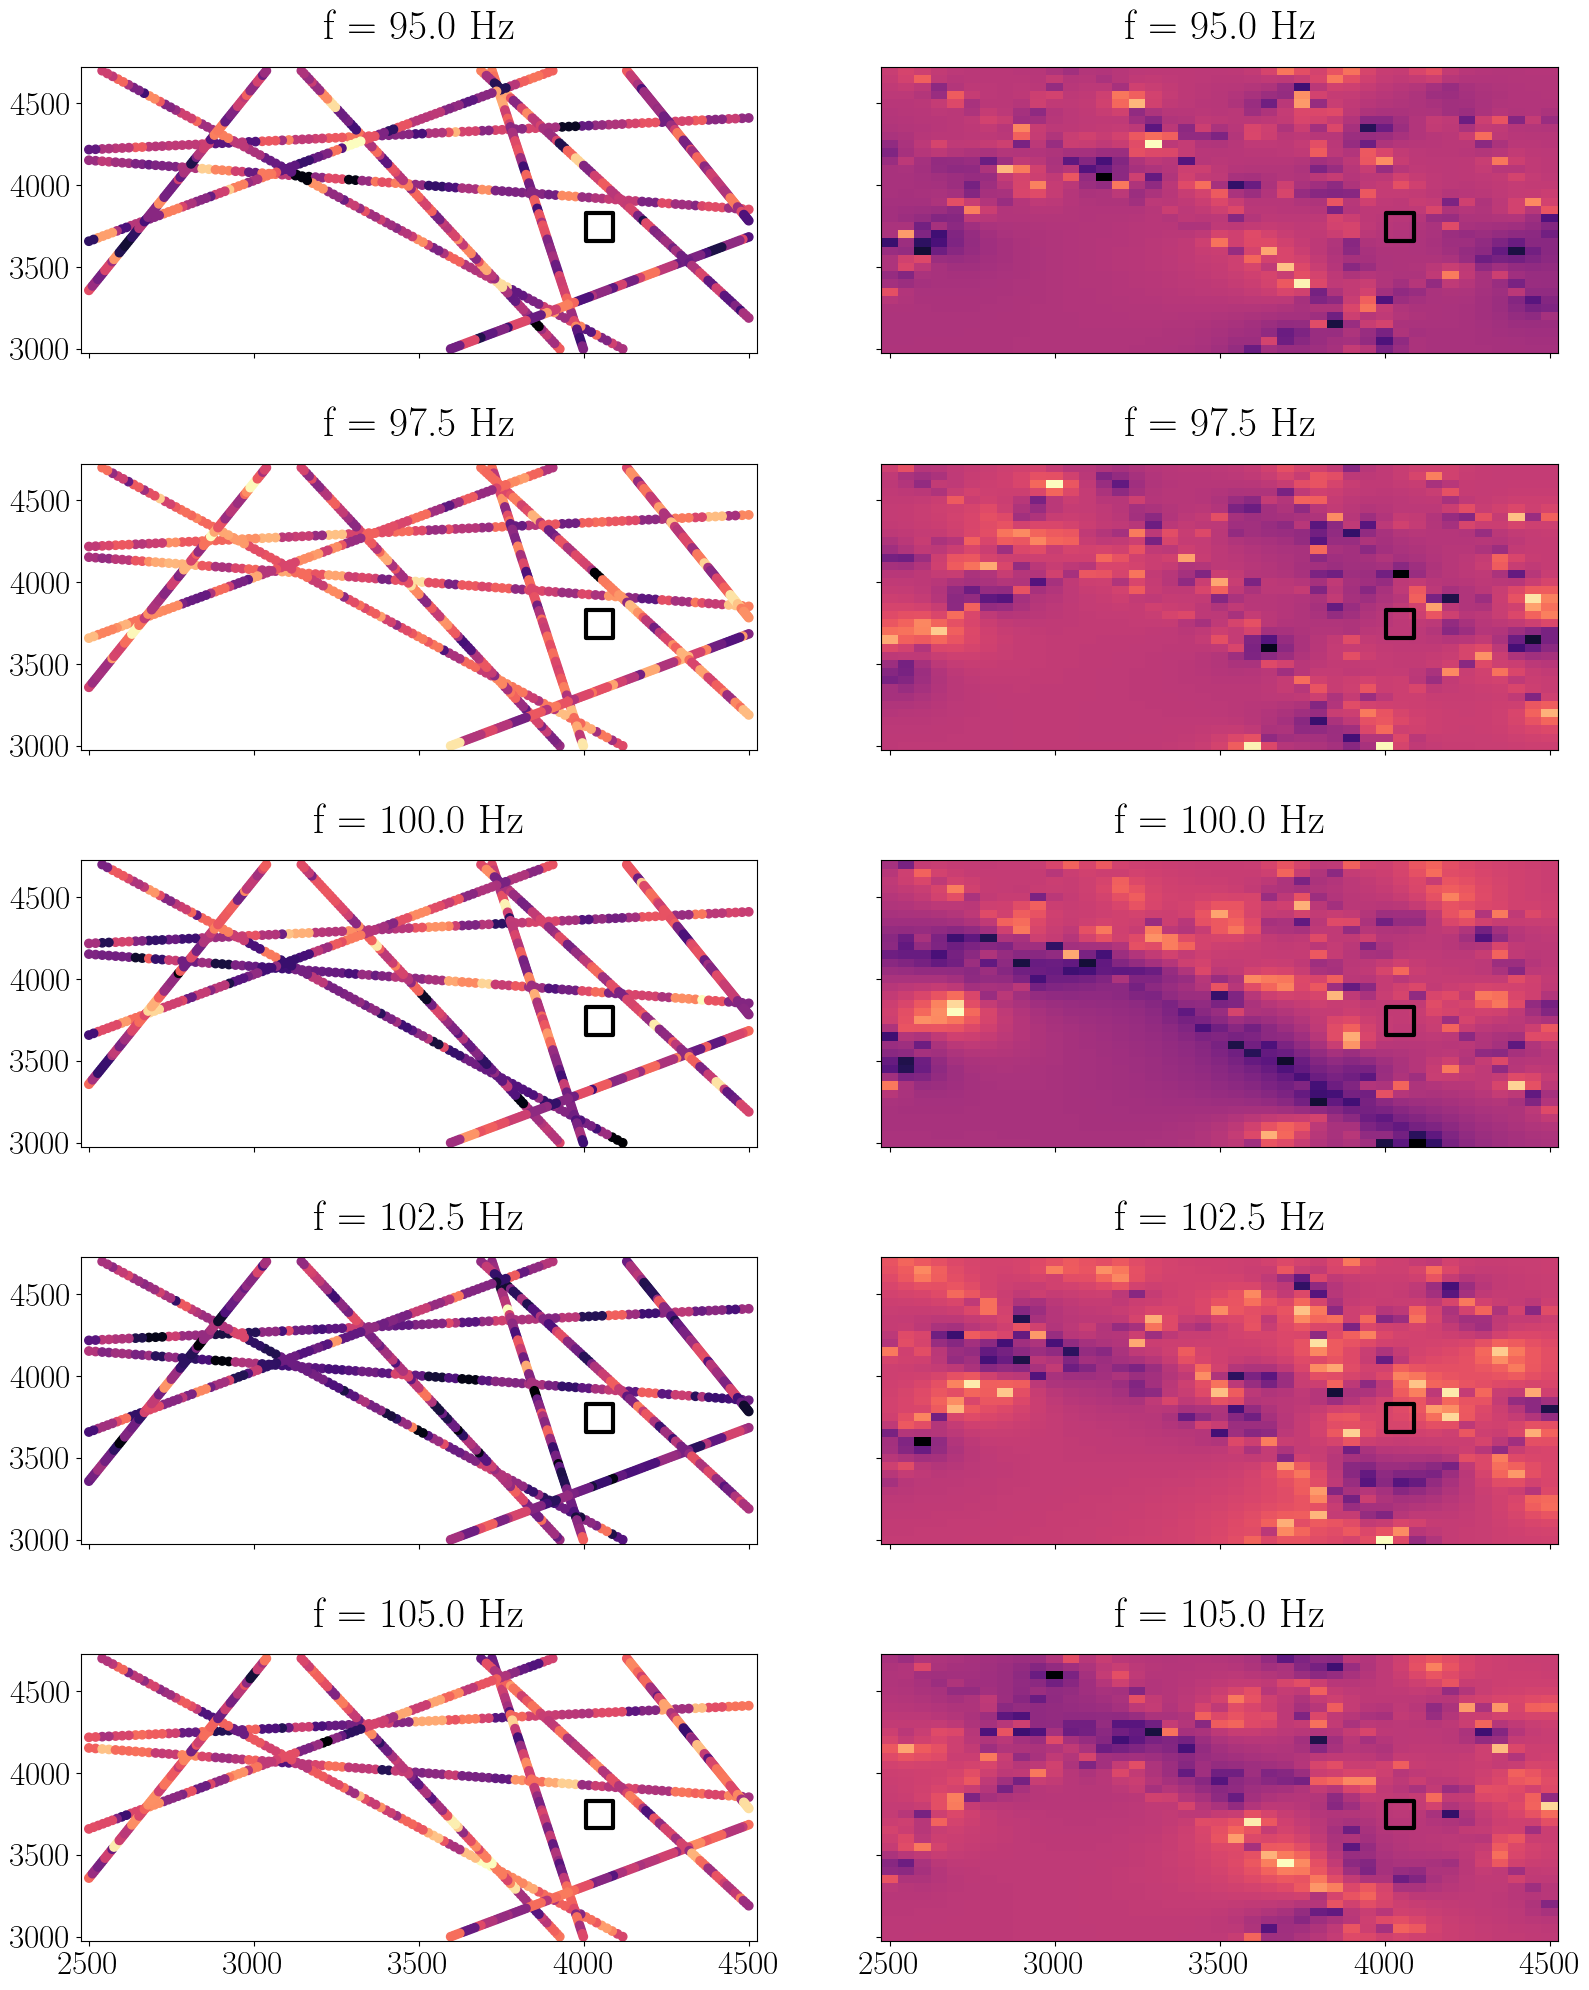

In [818]:

# if n_components <= 5:
#     comp_to_plot = np.arange(n_components)
# else:
#     comp_to_plot = np.linspace(0, n_components, num=5, endpoint=False).astype(int)

# ncomp = comp_to_plot.size 

# fig, axs = plt.subplots(ncomp, 3, figsize=(16, 4*ncomp), sharex=True)
# for i, icomp in enumerate(comp_to_plot):

# axs = axs.flatten()
freq_plot = [95, 97.5, 100, 102.5, 105]
fig, axs = plt.subplots(len(freq_plot), 2, figsize=(16, 4 * len(freq_plot)), sharex=True, sharey=True)

for i in range(len(freq_plot)):
    idx_f = np.argmin(np.abs(freq - freq_plot[i]))

    axs[i, 0].scatter(
        x_lib_sparse,
        y_lib_sparse,
        c=gamma_21_rr_sparse[idx_f, :],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    # psi_i_interp = coords_low_dim_grid[:, :, idx_f]
    axs[i, 1].pcolormesh(
        x,
        y,
        gamma_21_rr_sparse_grid[:, :, idx_f],
        cmap="magma",
        # vmin=-1,
        # vmax=1,
    )

    axs[i, 0].set_title(f"f = {freq[idx_f]} Hz")
    axs[i, 1].set_title(f"f = {freq[idx_f]} Hz")
    # axs[i, 1].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_pi[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )
    # axs[i, 2].scatter(
    #     x_lib_sparse,
    #     y_lib_sparse,
    #     c=coords_isompa_dcf[..., i],
    #     cmap="jet",
    #     vmin=0,
    #     vmax=1,
    # )


for ax in axs.flatten():
    # ax.scatter(x_rcv1, y_rcv1, label="RCV1")
    # ax.scatter(x_rcv2, y_rcv2, label="RCV2")
    ax.scatter(
        x0,
        y0,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="k",
        label="Target",
        linewidth=3,
    )

# plt.xlim(-d12, np.max(x))
# plt.ylim(-d12, np.max(y))
# plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2 * r0,
#         height=2 * r0,
#         angle=0,
#         theta1=np.atan(np.min(y) / np.max(x)) * 180 / np.pi,
#         theta2=np.atan(np.max(y) / np.min(x)) * 180 / np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--",
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

In [819]:
idx_x0 = np.argmin(np.abs(x - x0))
idx_y0 = np.argmin(np.abs(y - y0))
gamma_21_rr_sparse_grid_r0 = gamma_21_rr_sparse_grid[idx_y0, idx_x0, :]

In [820]:
gamma_a = gamma_21_rr_sparse_grid_r0[:, np.newaxis]
gamma_b = gamma_21_rr_sparse_grid.reshape(
    gamma_21_rr_sparse_grid.shape[0] * gamma_21_rr_sparse_grid.shape[1],
    gamma_21_rr_sparse_grid.shape[2],
).T
print(gamma_a.shape, gamma_b.shape)
dist_theta_gamma_sparse_grid = calc_gamma_dist(gamma_a=gamma_a, gamma_b=gamma_b, dist_type="theta")
dist_theta_gamma_sparse_grid /= np.max(dist_theta_gamma_sparse_grid)

ind_min_gamma_sparse_grid = np.argmin(dist_theta_gamma_sparse_grid)
xmin_gamma_sparse_grid, ymin_gamma_sparse_grid = (
    xx.flatten()[ind_min_gamma_sparse_grid],
    yy.flatten()[ind_min_gamma_sparse_grid],
)

(261, 1) (261, 1435)


In [821]:
dist_theta_gamma_sparse_grid = dist_theta_gamma_sparse_grid.reshape(
    gamma_21_rr_sparse_grid.shape[0:2]
)

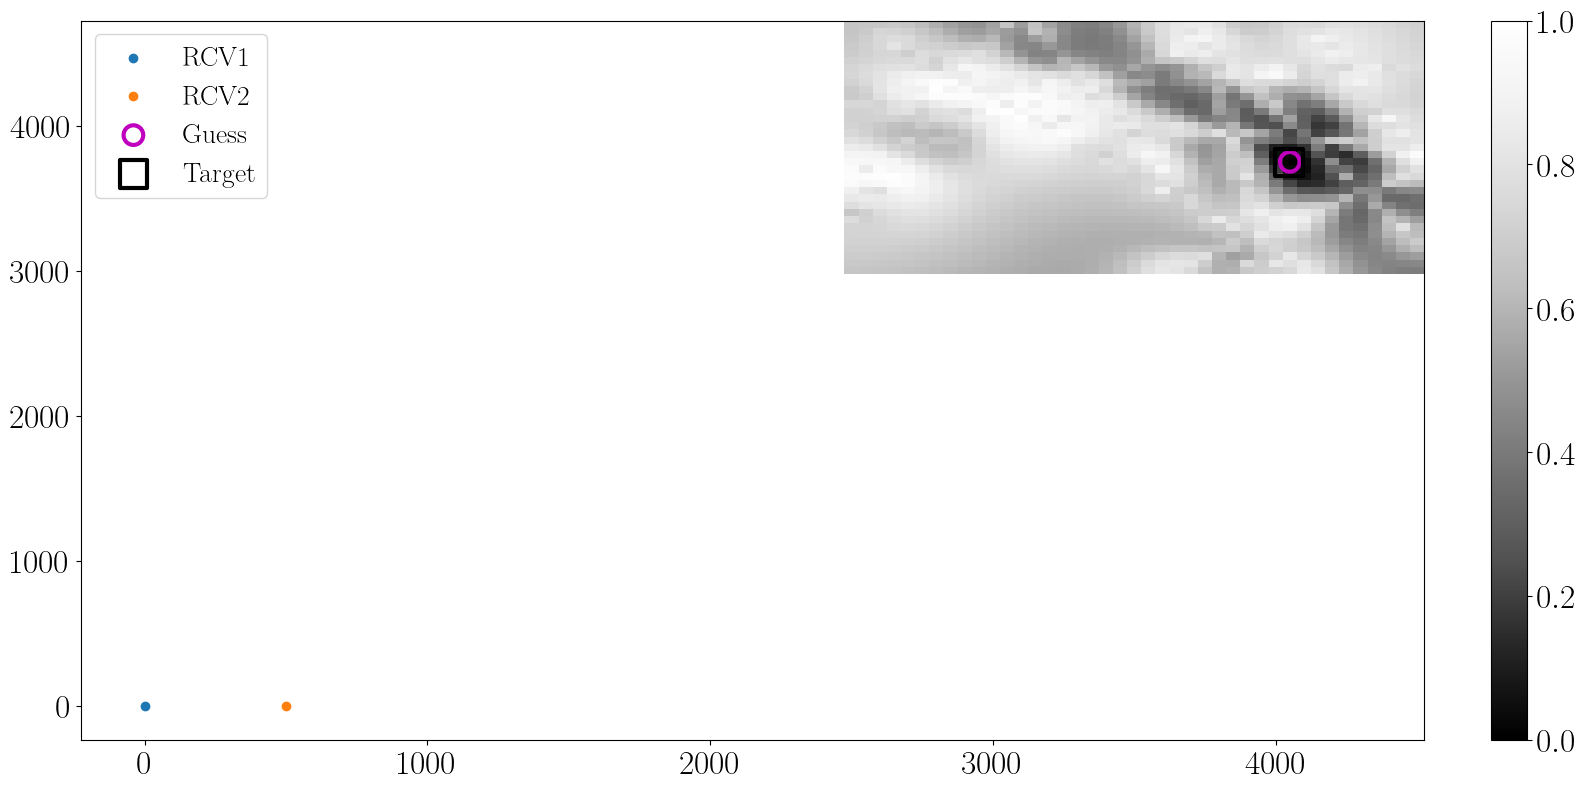

In [822]:
cmap = "Greys_r"
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)

im = axs[0].pcolormesh(x, y, dist_theta_gamma_sparse_grid, cmap=cmap, vmin=0, vmax=1)

axs[0].scatter(x_rcv1, y_rcv1, label="RCV1")
axs[0].scatter(x_rcv2, y_rcv2, label="RCV2")
axs[0].scatter(
    xmin_gamma_sparse_grid,
    ymin_gamma_sparse_grid,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[0].scatter(
    x0,
    y0,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="k",
    label="Target",
    linewidth=3,
)
axs[0].legend(loc="upper left")

# im = axs[1].pcolormesh(x, y, dist_theta_gamma, cmap=cmap, vmin=0, vmax=1)
# axs[1].scatter(x_rcv1, y_rcv1, label="RCV1")
# axs[1].scatter(x_rcv2, y_rcv2, label="RCV2")
# axs[1].scatter(
#     xmin_gamma,
#     ymin_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )
# axs[1].legend(loc="upper left")


# im = axs[2].pcolormesh(x, y, dist_c, cmap=cmap, vmin=0, vmax=1)

# axs[2].scatter(x_rcv1, y_rcv1, label="RCV1")

# axs[2].scatter(x_rcv2, y_rcv2, label="RCV2")

# axs[2].scatter(
#     xmin_c,
#     ymin_c,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[2].scatter(
#     x0,
#     y0,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="k",
#     label="Target",
#     linewidth=3,
# )

# axs[2].legend(loc="upper left")

# plt.xlim(-d12, np.max(x))

# plt.ylim(-d12, np.max(y))

plt.colorbar(im)

# # -------------------------------------------------------
# # Add circles corresponding to r = r10 and r = r20
# # -------------------------------------------------------
# from matplotlib.patches import Arc

# for ax in axs.flatten():

#     arc0 = Arc(
#         (0, 0),
#         width=2*r0,
#         height=2*r0,
#         angle=0,
#         theta1=np.atan(np.min(y)/np.max(x))*180/np.pi,
#         theta2=np.atan(np.max(y)/np.min(x))*180/np.pi,
#         color="r",
#         alpha=0.5,
#         linewidth=2,
#         linestyle="--"
#     )

#     ax.add_patch(arc0)


# set_subfigures_abc_labels(
#     axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
# )

**Bilan** 

Pas d'amélioration significative après apprentissage de variété. 
